# Predicting Hotel Booking Cancellations — a CRISP-DM Project

**Author:** `<your name>` · **Course:** CMPE 255 · **Repo:** [MeronDT/CMPE-255-Data-Mining-process](https://github.com/MeronDT/CMPE-255-Data-Mining-process) · **App:** `<deployed URL>`

**Data:** *Hotel booking demand datasets* — N. António, A. de Almeida & L. Nunes, *Data in Brief* 22 (2019) 41–49, [doi:10.1016/j.dib.2018.11.126](https://doi.org/10.1016/j.dib.2018.11.126). 119,390 bookings for a resort hotel (H1) and a city hotel (H2) in Portugal, arrivals July 2015 – August 2017. Mirrored on Kaggle as [`jessemostipak/hotel-booking-demand`](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) and in the [TidyTuesday repo](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11) (used here — no login needed).

This notebook follows the **CRISP-DM 1.0** reference model end to end: each phase is broken into its **generic tasks**, and each task produces the **outputs** CRISP-DM defines for it.

| # | Phase | Generic tasks |
|---|---|---|
| 1 | Business Understanding | Determine business objectives · Assess situation · Determine data mining goals · Produce project plan |
| 2 | Data Understanding | Collect initial data · Describe data · Explore data · Verify data quality |
| 3 | Data Preparation | Select · Clean · Construct · Integrate · Format data |
| 4 | Modeling | Select modeling technique · Generate test design · Build model · Assess model |
| 5 | Evaluation | Evaluate results · Review process · Determine next steps |
| 6 | Deployment | Plan deployment · Plan monitoring & maintenance · Produce final report · Review project |

**Headline result:** a random-forest model that scores each booking's cancellation risk at booking time. On the most recent 20 % of arrivals (never used for training or tuning) it reaches **ROC-AUC 0.868** and **precision 0.77** at a cost-optimised threshold, meeting both data mining success criteria, and is worth an estimated **€19,700 per 1,000 bookings** compared with doing nothing. It is deployed as a Streamlit app with single and batch scoring.

**How to run:** *Runtime → Run all* (≈ 7–10 min on free Colab). All figures, reports, the model and the app are written to `artifacts/`.

## ⚙️ Setup & configuration

In [1]:
import json, platform, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (8, 4.5)
print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


In [2]:
# ============================ CONFIGURATION ============================
BASE_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/"
SOURCES  = {"Resort Hotel": BASE_URL + "H1.csv", "City Hotel": BASE_URL + "H2.csv"}   # original per-hotel files
COMBINED_REFERENCE = BASE_URL + "hotels.csv"   # published combined file, used only to validate our integration

TARGET       = "is_canceled"   # 1 = booking cancelled
RANDOM_STATE = 42
TEST_SIZE    = 0.20            # most recent 20 % of arrivals held out (time-based split)
CV_FOLDS     = 5
N_TUNING_ITER = 6              # random-search iterations (lower = faster)

# Phase 1.3 data mining success criteria — fixed BEFORE modeling
SUCCESS_CRITERIA = {"roc_auc": 0.85, "precision": 0.75}

# Phase 1.2 cost/benefit assumptions (EUR per booking) — justify these in 1.2
VALUE_TP = 100.0   # cancellation correctly anticipated -> room re-sold / deposit secured (share of avg stay revenue)
COST_FP  = 100.0   # guest who would have arrived is treated as a likely canceller (walk to another hotel, goodwill)
COST_FN  = 0.0     # missed cancellation = today's status quo (loss happens with or without the model)
# =======================================================================

ART = Path("artifacts"); FIG, REP, MOD, APP = ART / "figures", ART / "reports", ART / "model", ART / "app"
for p in (FIG, REP, MOD, APP):
    p.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight"); plt.show()

---
# Phase 1 — Business Understanding
*Goal: understand the project objectives from a business perspective, convert them into a data mining problem definition, and draw up a preliminary plan.*

## 1.1 Determine business objectives

### Output: Background
The stakeholder is the revenue-management team of two hotels in Portugal — a resort hotel in the Algarve (H1) and a city hotel in Lisbon (H2) — whose booking records were published by António, de Almeida & Nunes (2019). Across July 2015 – August 2017, **37 % of all bookings were cancelled** (42 % in the city hotel). Cancellations are a structural problem in hospitality: free-cancellation policies and online travel agencies make it cheap for guests to book speculatively. A room released a few days before arrival is often impossible to re-sell, while the usual defence — overbooking by a fixed rule of thumb — risks "walking" guests (relocating them to another hotel) when more people turn up than expected. Today, neither hotel estimates cancellation risk per booking.

### Output: Business objectives
- **Primary objective:** reduce the revenue lost to cancellations by identifying high-risk bookings early enough to act (request a deposit, send a reminder, or count them in overbooking decisions).
- **Related business questions:** Which booking characteristics drive cancellation? Do the city and resort hotels behave differently? Which channels and customer types are riskiest?
- **Expected benefits:** higher occupancy, overbooking based on evidence instead of rules of thumb, targeted deposit policies.

### Output: Business success criteria
| Criterion | Measure | Target | Judged by |
|---|---|---|---|
| Revenue recovered | estimated net value per 1,000 bookings vs. the status quo, using the cost model in 1.2 | positive and clearly above "flag everything" | Revenue manager |
| Actionability | share of flagged bookings that really cancel (staff stop trusting flags that are usually wrong) | ≥ 75 % | Front-office manager |
| Usability | staff can score a booking or a daily file without technical help | working web app | Reservations team |

## 1.2 Assess situation

### Output: Inventory of resources
| Resource | Available |
|---|---|
| Personnel | the analyst (author); an AI assistant (Claude) for code review and expert critique; the course instructor |
| Data | 2 CSV files (H1 resort 40,060 rows; H2 city 79,330 rows), 31 attributes, open data |
| Computing | Google Colab (free tier), GitHub |
| Software | Python, pandas, scikit-learn, matplotlib, Streamlit; optionally IBM SPSS Modeler |

### Output: Requirements, assumptions and constraints
- **Requirements:** predictions may use **only information known when the booking is made**; results must be explainable to hotel staff; the model must be deployable as a simple web app; the work must be reproducible end to end.
- **Assumptions:** 2015–2017 booking behaviour is representative of future bookings; the published data is accurate (hotel and customer identifiers were removed by the authors).
- **Constraints:** no booking date or booking ID, no price history, no customer history beyond two counts; public data only; free-tier compute.

### Output: Risks and contingencies
| Risk | Likelihood | Impact | Contingency |
|---|---|---|---|
| Target leakage from fields filled in after booking | High | High | audit each attribute for "known at booking time?" (2.4, 3.1) and test sensitivity (5.2) |
| Behaviour shifts over time (concept drift) | Medium | High | time-based test split and time-series validation; drift monitoring (6.2) |
| Model misses the success criteria | Medium | Medium | feature construction, tuning; revisit goals (5.3) |
| Data-quality quirks (e.g. odd deposit codes) | Medium | Medium | investigate and document (2.3, 2.4) |

### Output: Terminology
| Term | Meaning |
|---|---|
| ADR | Average Daily Rate — revenue per occupied room-night (EUR) |
| Lead time | days between booking and arrival |
| No-show | guest neither cancelled nor arrived (counted as a cancellation here) |
| Overbooking / "walking" a guest | selling more rooms than exist; relocating a guest when everyone shows up |
| ROC-AUC | probability that the model ranks a random cancellation above a random non-cancellation |
| Precision / recall | share of flagged bookings that really cancel / share of cancellations that are flagged |

### Output: Costs and benefits
The average booking is worth about **€358** (mean ADR €101.8 × mean stay 3.43 nights). The values below feed `VALUE_TP`, `COST_FP`, `COST_FN` and the business evaluation in 5.1:

| Outcome | Business meaning | Assumed value | Reasoning |
|---|---|---|---|
| True positive | cancellation anticipated → room re-sold or deposit secured | +€100 | ≈ 28 % of an average booking's revenue recovered |
| False positive | an arriving guest is treated as a likely canceller → room oversold, guest walked | −€100 | cost of a comparable room elsewhere, transport and goodwill ≈ one night's ADR |
| False negative | cancellation not anticipated → same as today | €0 | the loss happens with or without the model |
| True negative | normal booking, no action | €0 | — |

These are assumptions; the decision threshold should be re-derived if the hotel supplies its own figures.

## 1.3 Determine data mining goals

### Output: Data mining goals
Build a **binary classifier** that estimates, **at booking time**, the probability that a booking will be cancelled (`is_canceled = 1`, including no-shows). One row = one booking. Secondary goal: identify the main drivers of cancellation.

### Output: Data mining success criteria
| Metric | Threshold | Why |
|---|---|---|
| ROC-AUC on the most recent 20 % of arrivals | ≥ 0.85 | the model must rank risky bookings well for targeting |
| Precision at the chosen decision threshold | ≥ 0.75 | 3 of 4 flagged bookings must truly cancel, or staff will ignore the flags |

## 1.4 Produce project plan

### Output: Project plan
| Phase | Duration (planned) | Resources | Outputs | Risks / dependencies |
|---|---|---|---|---|
| Business Understanding | 1 day | analyst, AI critic | sections 1.1–1.4 | — |
| Data Understanding | 1 day | Colab | data description, exploration and quality reports | data access |
| Data Preparation | 1–2 days | Colab | modeling dataset + reports | leakage decisions |
| Modeling | 1 day | Colab | candidate and tuned models | compute time on free tier |
| Evaluation | 1 day | analyst, AI critic | approved model, business case | criteria not met → iterate |
| Deployment | 1–2 days | Streamlit Cloud, GitHub | app, monitoring plan, report, article, video | hosting |

Iterations expected: Data Preparation ↔ Modeling (feature and leakage decisions), and Evaluation → Business Understanding if the criteria are not met. Both happened (see the critic logs): the validation design was changed after the first evaluation.

### Output: Initial assessment of tools and techniques
Python and scikit-learn in Colab make the whole project reproducible from one notebook. Candidate techniques: **logistic regression** as an interpretable benchmark; **random forest** and **gradient boosting** for non-linear effects and interactions (e.g. lead time × deposit type × market segment). Streamlit gives a free, code-based deployment. IBM SPSS Modeler would support the same CRISP-DM flow visually but adds licensing; it was not needed.

### 🔍 Critic review — Business Understanding

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Business Understanding** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: whether the business objective, business success criteria and data mining success criteria are measurable and consistent with each other, and whether the cost/benefit assumptions are realistic and justified. List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Cost figures were unjustified and the false-positive cost (€40) looked too low next to the cost of walking a guest; precision target needed a rationale. | Derived costs from the average booking (€358): +€100 / −€100; justified the 75 % precision target as staff trust. |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
# Phase 2 — Data Understanding
*Goal: collect the data, describe and explore it, and verify its quality.*

## 2.1 Collect initial data

In [3]:
originals = {hotel: pd.read_csv(url) for hotel, url in SOURCES.items()}
collection = pd.DataFrame([{"hotel": h, "source": SOURCES[h].split("/")[-1], "rows": len(d), "columns": d.shape[1]}
                           for h, d in originals.items()])
collection.to_csv(REP / "initial_data_collection.csv", index=False)
display(collection)
originals["Resort Hotel"].head(3)

,hotel,source,rows,columns
0,Resort Hotel,H1.csv,40060,31
1,City Hotel,H2.csv,79330,31


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02


### Output: Initial data collection report
| Item | Detail |
|---|---|
| Source | António, de Almeida & Nunes (2019), *Data in Brief*; files H1.csv (resort) and H2.csv (city) via the TidyTuesday mirror |
| Retrieval | direct HTTPS download with pandas (no credentials) |
| Size | 40,060 + 79,330 = 119,390 bookings, 31 attributes each |
| Problems encountered | two separate files with **no hotel identifier**; inconsistent formatting between and within them (see 2.2) |
| Data wanted but unavailable | booking date and booking ID, price paid vs. list price, customer history across stays, local events and weather |

## 2.2 Describe data

In [4]:
# How consistent are the two files?
a, b = originals["Resort Hotel"], originals["City Hotel"]
fmt = pd.DataFrame({"resort_dtype": a.dtypes.astype(str), "city_dtype": b.dtypes.astype(str)})
fmt["padded_text"] = [a[c].astype(str).str.match(r"^\s|.*\s$").any() for c in a.columns]
fmt["literal_NULL"] = [int((a[c].astype(str).str.strip() == "NULL").sum() + (b[c].astype(str).str.strip() == "NULL").sum()) for c in a.columns]
inconsistent = fmt[(fmt.resort_dtype != fmt.city_dtype) | fmt.padded_text | (fmt.literal_NULL > 0)]
print("Columns with format problems:"); display(inconsistent)

Columns with format problems:


,resort_dtype,city_dtype,padded_text,literal_NULL
Children,int64,float64,False,0
Meal,str,str,True,0
ReservedRoomType,str,str,True,0
AssignedRoomType,str,str,True,0
DepositType,str,str,True,0
Agent,str,str,True,16340
Company,str,str,True,112593


In [5]:
import re

def harmonize(d, hotel):
    """Standardise one source file: snake_case names, trimmed text, 'NULL' -> missing, hotel label."""
    d = d.copy()
    d.columns = [re.sub(r"(?<!^)(?=[A-Z][a-z])", "_", c).lower() for c in d.columns]   # IsCanceled -> is_canceled, ADR -> adr
    for c in d.select_dtypes(exclude="number").columns:
        d[c] = d[c].astype(str).str.strip().replace({"NULL": np.nan, "nan": np.nan, "": np.nan})
    for c in ("agent", "company", "children"):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d.insert(0, "hotel", hotel)
    return d

# Stack both hotels for exploration (formally validated in 3.4 Integrate data)
raw = pd.concat([harmonize(d, h) for h, d in originals.items()], ignore_index=True)

MEANING = {
    "hotel": "Resort Hotel (H1) or City Hotel (H2)", "is_canceled": "TARGET: 1 if cancelled (incl. no-show)",
    "lead_time": "days between booking and arrival", "arrival_date_year": "arrival year",
    "arrival_date_month": "arrival month", "arrival_date_week_number": "arrival ISO week",
    "arrival_date_day_of_month": "arrival day", "stays_in_weekend_nights": "Sat/Sun nights booked",
    "stays_in_week_nights": "Mon–Fri nights booked", "adults": "number of adults", "children": "number of children",
    "babies": "number of babies", "meal": "meal package (BB, HB, FB, SC/Undefined = none)",
    "country": "country of origin (ISO 3166-1 alpha-3)", "market_segment": "market segment (TA = travel agent, TO = tour operator)",
    "distribution_channel": "booking distribution channel", "is_repeated_guest": "1 if guest stayed before",
    "previous_cancellations": "prior bookings cancelled by this customer", "previous_bookings_not_canceled": "prior bookings not cancelled",
    "reserved_room_type": "room type reserved (code)", "assigned_room_type": "room type assigned at check-in (code)",
    "booking_changes": "changes made to the booking until check-in/cancellation", "deposit_type": "No Deposit / Non Refund / Refundable",
    "agent": "ID of travel agency (missing = none)", "company": "ID of company paying (missing = none)",
    "days_in_waiting_list": "days on waiting list before confirmation", "customer_type": "Transient, Contract, Group, Transient-Party",
    "adr": "average daily rate (EUR)", "required_car_parking_spaces": "parking spaces requested",
    "total_of_special_requests": "special requests made", "reservation_status": "last status: Canceled, Check-Out, No-Show",
    "reservation_status_date": "date the last status was set",
}
dd = pd.DataFrame({"meaning": pd.Series(MEANING), "dtype": raw.dtypes.astype(str),
                   "missing_%": (raw.isna().mean() * 100).round(2), "n_unique": raw.nunique(),
                   "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)}).loc[raw.columns]
dd.to_csv(REP / "data_description.csv")
print(f"{raw.shape[0]:,} bookings x {raw.shape[1]} attributes"); display(dd)

119,390 bookings x 32 attributes


,meaning,dtype,missing_%,n_unique,example
hotel,Resort Hotel (H1) or City Hotel (H2),str,0.00,2,Resort Hotel
is_canceled,TARGET: 1 if cancelled (incl. no-show),int64,0.00,2,0
lead_time,days between booking and arrival,int64,0.00,479,342
arrival_date_year,arrival year,int64,0.00,3,2015
arrival_date_month,arrival month,str,0.00,12,July
arrival_date_week_number,arrival ISO week,int64,0.00,53,27
arrival_date_day_of_month,arrival day,int64,0.00,31,1
stays_in_weekend_nights,Sat/Sun nights booked,int64,0.00,17,0
stays_in_week_nights,Mon–Fri nights booked,int64,0.00,35,0
adults,number of adults,int64,0.00,14,2


### Output: Data description report
The integrated data has **119,390 bookings × 32 attributes** (31 original + `hotel`): 16–17 integer, 1–2 float and 13 text fields per file. Units: money in EUR (`adr`), durations in days or nights.

Format problems found and fixed in `harmonize()`: `Children` is an integer in one file and a float in the other; `Meal`, `ReservedRoomType`, `AssignedRoomType` and `DepositType` are padded with spaces; `Agent` and `Company` store missing values as the text `"NULL"` (16,340 and 112,593 times). Column names are CamelCase in the source and are converted to snake_case.

Against the Phase 1 requirement "known at booking time", three groups emerge: clearly known at booking (lead time, dates, stay length, guests, meal, segment, channel, deposit, ADR…); **only known after the outcome** (`reservation_status`, `reservation_status_date`, `assigned_room_type`); and **ambiguous** (`booking_changes`, `required_car_parking_spaces`, `total_of_special_requests`, `country`), which can be updated between booking and arrival. 2.4 and 5.2 deal with these.

## 2.3 Explore data

Overall cancellation rate: 37.0%


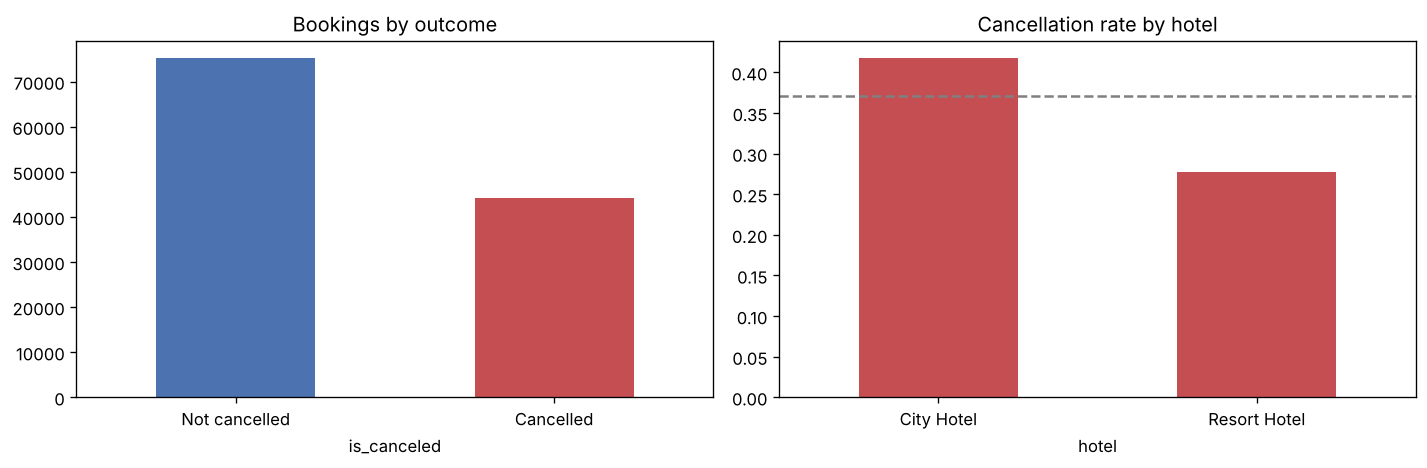

In [6]:
rate = raw[TARGET].mean()
print(f"Overall cancellation rate: {rate:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw[TARGET].map({0: "Not cancelled", 1: "Cancelled"}).value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0, title="Bookings by outcome")
raw.groupby("hotel")[TARGET].mean().plot.bar(ax=axes[1], color="#C44E52", rot=0, title="Cancellation rate by hotel")
axes[1].axhline(rate, ls="--", c="gray"); savefig("eda_target")

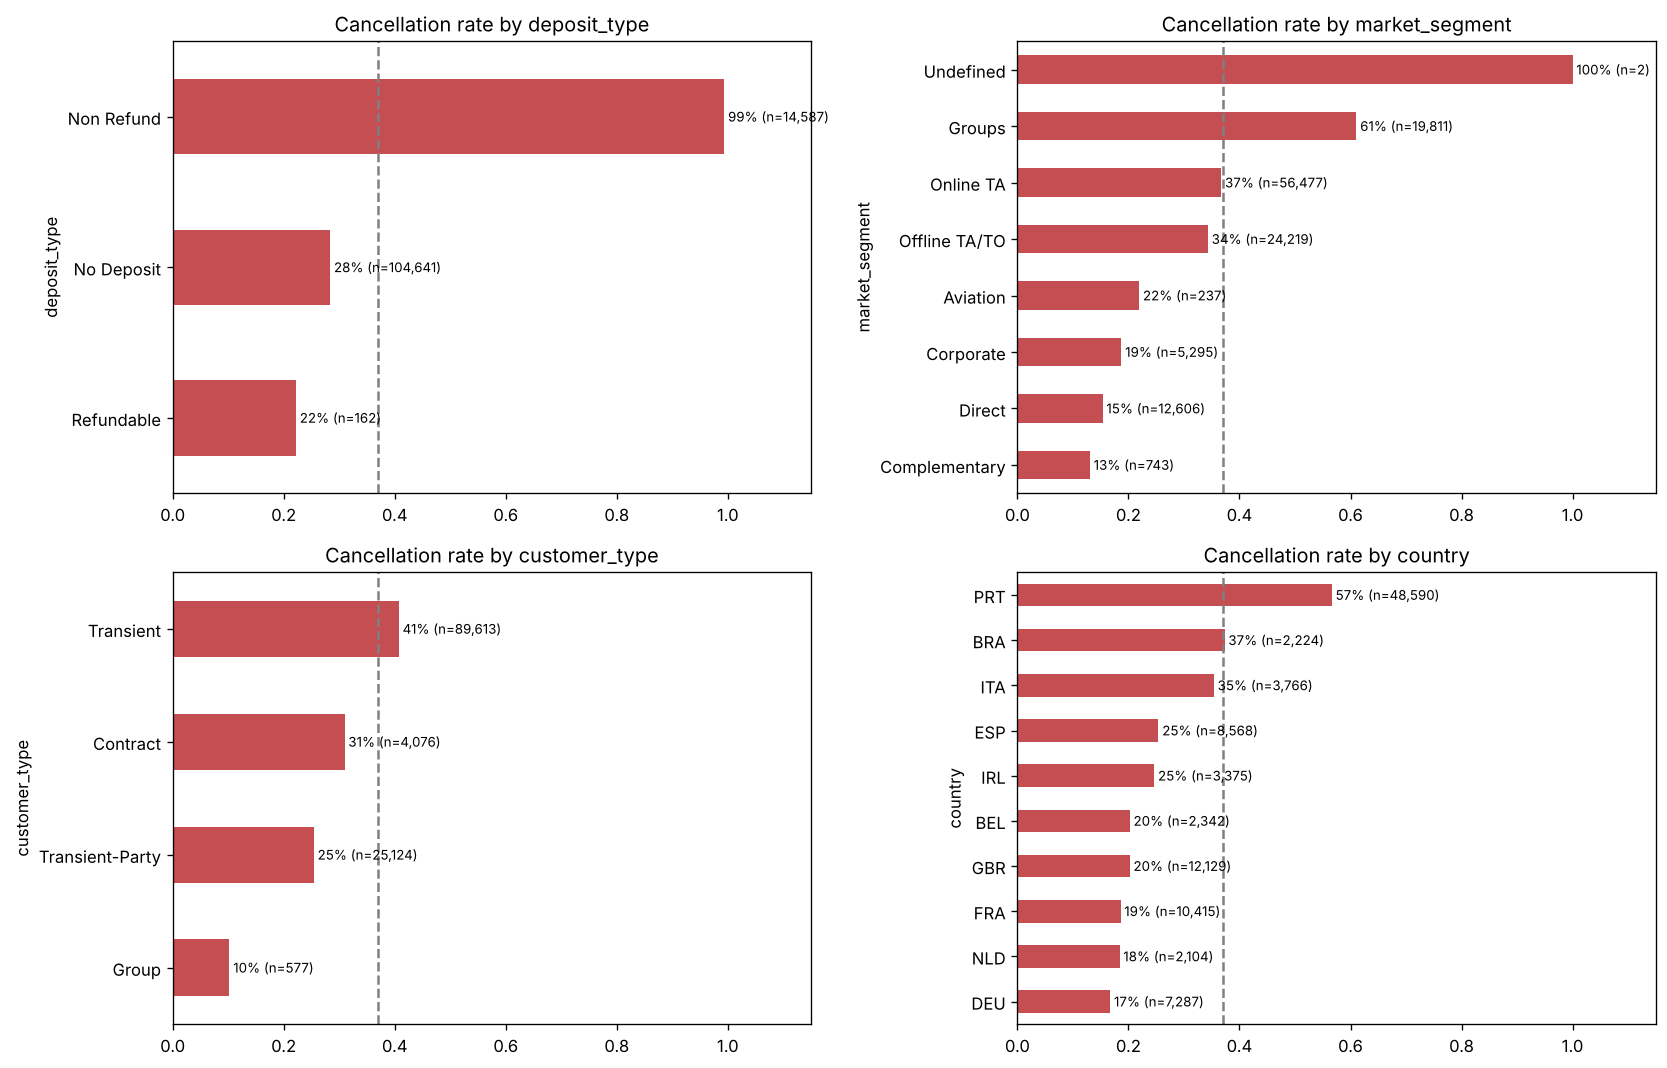

In [7]:
def rate_plot(col, order=None, top=None, ax=None):
    g = raw.groupby(col)[TARGET].agg(["mean", "size"])
    if top: g = g.sort_values("size", ascending=False).head(top)
    g = g.reindex(order) if order else g.sort_values("mean")
    g["mean"].plot.barh(ax=ax, color="#C44E52", title=f"Cancellation rate by {col}")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m, i, f" {m:.0%} (n={n:,})", va="center", fontsize=8)
    ax.axvline(rate, ls="--", c="gray"); ax.set_xlim(0, 1.15)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rate_plot("deposit_type", ax=axes[0, 0]); rate_plot("market_segment", ax=axes[0, 1])
rate_plot("customer_type", ax=axes[1, 0]); rate_plot("country", top=10, ax=axes[1, 1])
savefig("eda_rates_categorical")

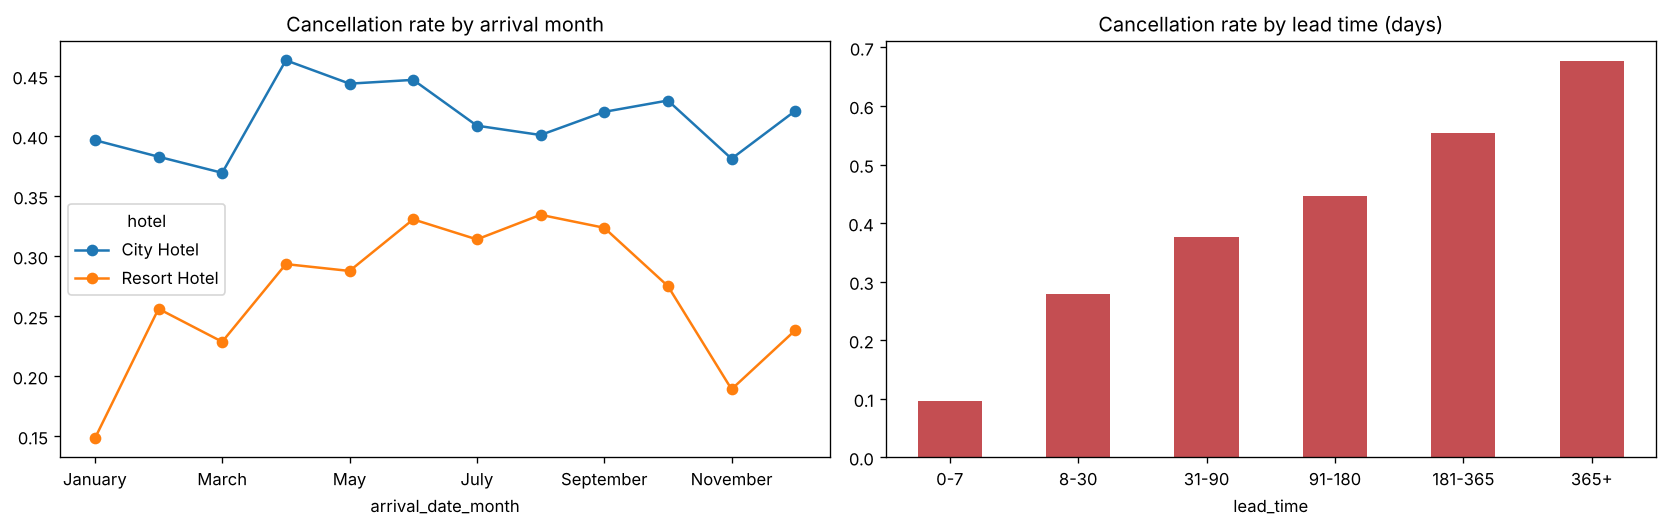

In [8]:
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
raw.pivot_table(index="arrival_date_month", columns="hotel", values=TARGET).reindex(months).plot(ax=axes[0], marker="o", title="Cancellation rate by arrival month")
bins = [-1, 7, 30, 90, 180, 365, 1000]
raw.groupby(pd.cut(raw["lead_time"], bins, labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]), observed=True)[TARGET].mean() \
   .plot.bar(ax=axes[1], color="#C44E52", rot=0, title="Cancellation rate by lead time (days)")
savefig("eda_month_leadtime")

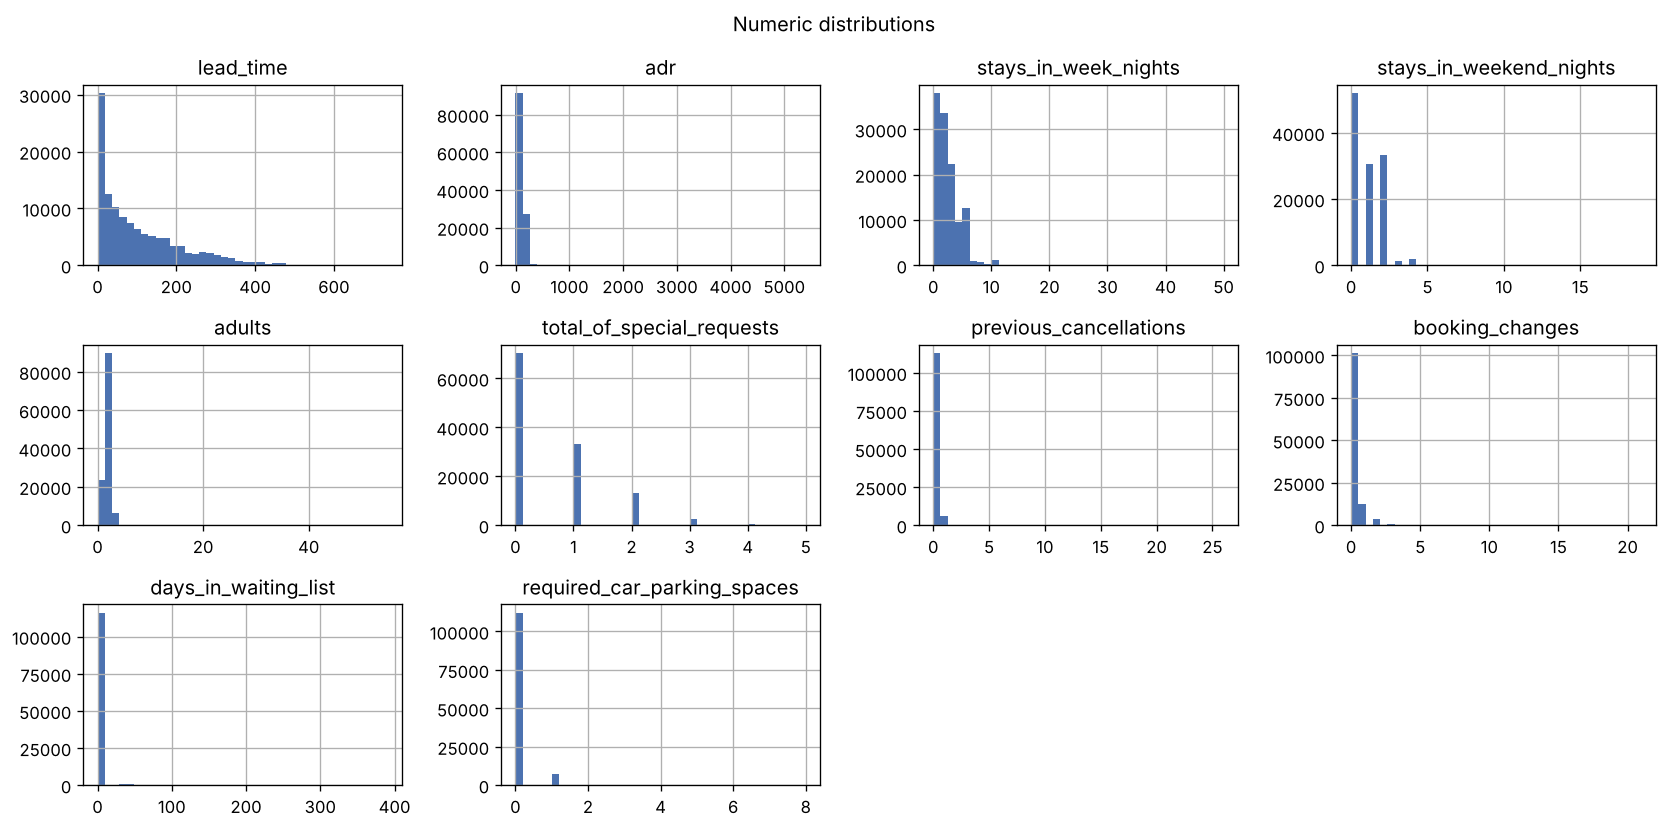

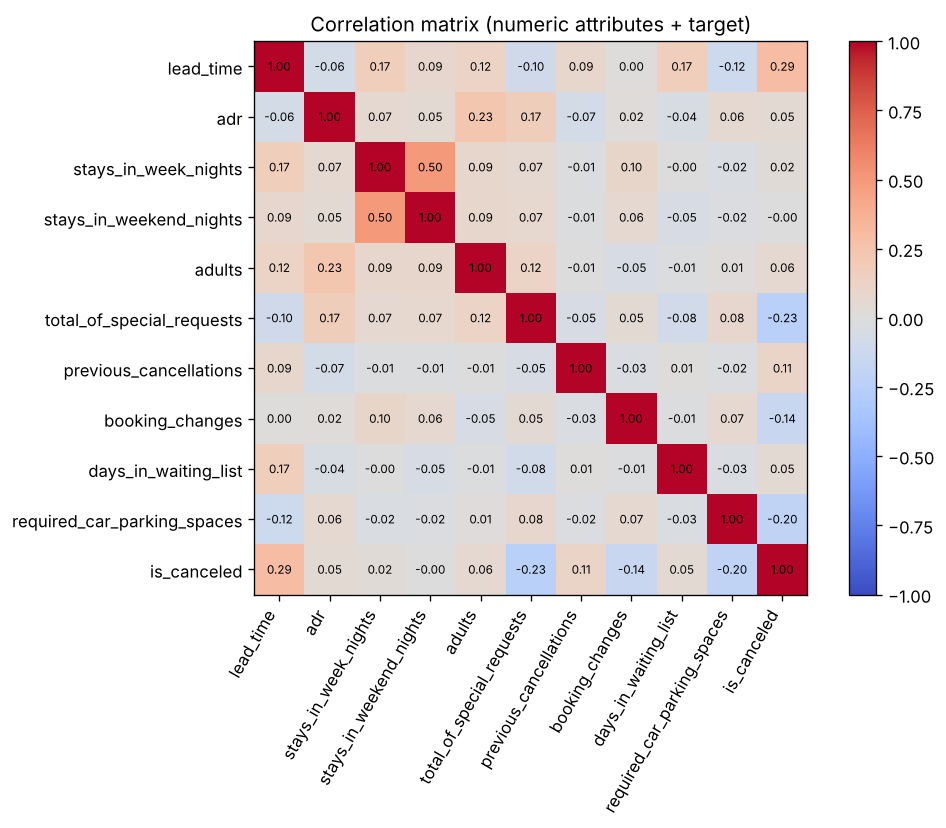

In [9]:
num_cols = ["lead_time", "adr", "stays_in_week_nights", "stays_in_weekend_nights", "adults", "total_of_special_requests",
            "previous_cancellations", "booking_changes", "days_in_waiting_list", "required_car_parking_spaces"]
raw[num_cols].hist(bins=40, figsize=(14, 7), layout=(3, 4), color="#4C72B0"); plt.suptitle("Numeric distributions"); savefig("eda_numeric_hist")

corr = raw[num_cols + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Correlation matrix (numeric attributes + target)"); savefig("eda_correlation")

In [10]:
# Critique fix: investigate the 'Non Refund' anomaly instead of just noting it
nr, rest = raw[raw["deposit_type"] == "Non Refund"], raw[raw["deposit_type"] != "Non Refund"]
profile = lambda d: [len(d), d[TARGET].mean(), (d["country"] == "PRT").mean(),
                     d["market_segment"].isin(["Groups", "Offline TA/TO"]).mean(), d["total_of_special_requests"].mean(),
                     d["lead_time"].median()]
nr_table = pd.DataFrame({"Non Refund": profile(nr), "all other bookings": profile(rest)},
                        index=["bookings", "cancellation rate", "share from Portugal", "share Groups or Offline TA/TO",
                               "mean special requests", "median lead time (days)"]).round(3)
nr_table.to_csv(REP / "non_refund_investigation.csv"); display(nr_table)

,Non Refund,all other bookings
bookings,14587.000,104803.000
cancellation rate,0.994,0.284
share from Portugal,0.972,0.328
share Groups or Offline TA/TO,0.972,0.285
mean special requests,0.002,0.651
median lead time (days),183.000,57.000


### Output: Data exploration report
| # | Finding | Hypothesis / implication |
|---|---|---|
| 1 | The city hotel cancels far more than the resort (41.7 % vs 27.8 %) | include `hotel`; evaluate performance per hotel (5.1) |
| 2 | Cancellation rises steadily with lead time: 9.6 % for bookings made ≤ 7 days ahead, 56 % at 6–12 months, 68 % beyond a year (correlation 0.29) | `lead_time` will be a key driver |
| 3 | **Non Refund deposits cancel 99.4 % of the time** — the opposite of what a non-refundable deposit should do. The investigation table shows these 14,587 bookings are 97 % from Portugal, 97 % Groups or offline tour-operator bookings, have no special requests and a median lead time of 183 days. | Most likely **block allocations** by tour operators recorded as "non refund" and later released, not individual guests forfeiting money. Keep the attribute (known at booking) but report it as a data-quality question for the hotel. |
| 4 | Guests from Portugal cancel 57 % of the time vs 17–37 % for the main foreign markets; 62 % of cancelled bookings are Portuguese vs 28 % of arrived ones | partly explained by finding 3; **also a leakage risk** if nationality is only confirmed at check-in (cancelled bookings keep a default value) → sensitivity test in 5.2 |
| 5 | Groups (61 %) and online travel agents (37 %) cancel most; direct (15 %) and corporate (19 %) bookings least; special requests go with commitment (correlation −0.23) | keep `market_segment`, `distribution_channel`, `total_of_special_requests` |
| 6 | Seasonality differs by hotel: the resort's cancellation rate ranges from 15 % (January) to 33 % (August); the city hotel stays at 37–46 % year round | keep month/week; expect seasonal drift in monitoring |

## 2.4 Verify data quality

In [11]:
n = len(raw)
quality = pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2)})
issues = {
    "Exact duplicate rows": int(raw.duplicated().sum()),
    "Bookings with 0 guests (adults+children+babies)": int((raw[["adults", "children", "babies"]].fillna(0).sum(axis=1) == 0).sum()),
    "Negative ADR": int((raw["adr"] < 0).sum()),
    "ADR > 1,000 EUR": int((raw["adr"] > 1000).sum()),
    "Bookings with 0 nights": int(((raw["stays_in_week_nights"] + raw["stays_in_weekend_nights"]) == 0).sum()),
    "Meal = 'Undefined' (same as 'SC' per data paper)": int((raw["meal"] == "Undefined").sum()),
}
print(pd.Series(issues).to_string()); display(quality[quality["missing"] > 0])
pd.Series(issues, name="count").to_csv(REP / "data_quality_issues.csv")
quality.to_csv(REP / "data_quality_missing.csv")

def leakage_suspects(df, target, max_levels=30, min_share=0.01):
    """Flag attributes where a sizeable group has a (near-)deterministic outcome — a classic sign of leakage."""
    rows = []
    for c in df.columns.drop(target):
        if df[c].nunique() > max_levels: continue
        g = df.groupby(c)[target].agg(["mean", "size"]); g = g[g["size"] >= min_share * len(df)]
        pure = g[(g["mean"] <= 0.01) | (g["mean"] >= 0.99)]
        if len(pure):
            rows.append({"attribute": c, "pure_groups": ", ".join(f"{k}→{m:.1%} (n={s:,})" for k, (m, s) in pure.iterrows())})
    return pd.DataFrame(rows)

suspects = leakage_suspects(raw, TARGET)
suspects.to_csv(REP / "leakage_suspects.csv", index=False)
print("\nLeakage suspects (groups with ≥99 % or ≤1 % cancellation):"); display(suspects)

Exact duplicate rows                                31994
Bookings with 0 guests (adults+children+babies)       180
Negative ADR                                            1
ADR > 1,000 EUR                                         1
Bookings with 0 nights                                715
Meal = 'Undefined' (same as 'SC' per data paper)     1169


,missing,missing_%
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31



Leakage suspects (groups with ≥99 % or ≤1 % cancellation):


,attribute,pure_groups
0,deposit_type,"Non Refund→99.4% (n=14,587.0)"
1,required_car_parking_spaces,"1→0.0% (n=7,383.0)"
2,reservation_status,"Canceled→100.0% (n=43,017.0), Check-Out→0.0% (..."


### Output: Data quality report
| Problem | Extent | Remedy |
|---|---|---|
| `reservation_status`, `reservation_status_date` | perfectly reveal the outcome (100 % / 0 % cancellation by status) | **exclude** (target leakage) |
| `assigned_room_type` | set at check-in | **exclude** (not known at booking time) |
| `booking_changes` | accumulates after booking | **exclude** |
| `required_car_parking_spaces` | 0 cancellations among 7,416 bookings with parking → almost certainly recorded at arrival | **exclude**; sensitivity tested in 5.2 |
| `total_of_special_requests`, `country` | can be added/corrected after booking | keep, sensitivity tested in 5.2 |
| `deposit_type = Non Refund` cancels 99.4 % | 14,587 bookings, mostly group/tour-operator blocks | keep; flagged as a question for the hotel |
| `company` missing | 94.3 % | replace by a `has_company` flag (missing = no company) |
| `agent` missing | 13.7 % | category `none` (missing = booked without an agent) |
| `country` missing | 488 bookings (0.4 %) | category `missing` — not the mode, which would label them Portuguese |
| `children` missing | 4 bookings | median imputation inside the pipeline |
| Exact duplicate rows | 31,994 (27 %) | **keep**: there is no booking ID and identical rows are plausibly separate rooms of a group booking — but this forces group-aware/time-based validation (Phase 4) |
| 0-guest bookings, negative ADR, ADR > €1,000 | 180, 1, 1 | drop rows |
| 0-night bookings | 715 | keep (day-use rooms are legitimate) |
| `meal = Undefined` | 1,169 | recode as `SC` (no meal package), as defined in the data paper |

### 🔍 Critic review — Data Understanding

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Data Understanding** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: whether each hypothesis is testable, whether data quality issues are quantified, and whether every attribute was audited for availability at booking time (target leakage). List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Non Refund anomaly noted but not investigated; `country` may be corrected at check-in (possible leakage). | Added a Non Refund profile (97 % Portuguese group/tour-operator blocks); planned a sensitivity test for `country` (done in 5.2). |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
# Phase 3 — Data Preparation
*Goal: construct the final modeling dataset. Outputs: **Dataset** and **Dataset description**.*

## 3.1 Select data

In [12]:
EXCLUDE = {
    "reservation_status": "encodes the outcome (Canceled / No-Show / Check-Out) - target leakage",
    "reservation_status_date": "date the outcome was recorded - known only after the fact",
    "assigned_room_type": "assigned at check-in - not known at booking time",
    "booking_changes": "accumulates after the booking is made - unknown at prediction time",
    "required_car_parking_spaces": "no cancellations among bookings with parking - likely recorded at arrival",
    "arrival_date_year": "calendar year does not generalise to future bookings",
    "arrival_date": "used only to order bookings for the time-based split",
    "agent": "replaced by categorical agent_id (3.3)",
    "company": "94 % missing - replaced by has_company flag (3.3)",
}
selection_log = pd.DataFrame([{"attribute": c, "decision": "exclude" if c in EXCLUDE else "include",
                               "rationale": EXCLUDE.get(c, "known at booking time, potentially predictive")}
                              for c in list(raw.columns) + ["arrival_date"] if c != TARGET])
selection_log.to_csv(REP / "rationale_for_inclusion_exclusion.csv", index=False)
display(selection_log)

,attribute,decision,rationale
0,hotel,include,"known at booking time, potentially predictive"
1,lead_time,include,"known at booking time, potentially predictive"
2,arrival_date_year,exclude,calendar year does not generalise to future bo...
3,arrival_date_month,include,"known at booking time, potentially predictive"
4,arrival_date_week_number,include,"known at booking time, potentially predictive"
5,arrival_date_day_of_month,include,"known at booking time, potentially predictive"
6,stays_in_weekend_nights,include,"known at booking time, potentially predictive"
7,stays_in_week_nights,include,"known at booking time, potentially predictive"
8,adults,include,"known at booking time, potentially predictive"
9,children,include,"known at booking time, potentially predictive"


### Output: Rationale for inclusion/exclusion
Attributes are excluded for one of three reasons: they **encode the outcome** (`reservation_status`, `reservation_status_date`), they are **set or updated after booking** (`assigned_room_type`, `booking_changes`, `required_car_parking_spaces`), or they would **not generalise** (`arrival_date_year` — future bookings have unseen years). `agent` and `company` are replaced by better representations in 3.3. Every other attribute is known at booking time and plausibly related to cancellation (2.3). Rows removed in 3.2 are invalid records (no guests, impossible prices) — 182 bookings, 0.15 %. Whether the ambiguous attributes leak is measured in 5.2.

## 3.2 Clean data

In [13]:
df = raw.copy(); log = []
def record(action, before, after):
    log.append({"action": action, "rows_before": before, "rows_after": after, "affected": before - after})

b = len(df); df = df[df[["adults", "children", "babies"]].fillna(0).sum(axis=1) > 0]; record("Drop bookings with 0 guests", b, len(df))
b = len(df); df = df[(df["adr"] >= 0) & (df["adr"] <= 1000)];                        record("Drop ADR < 0 or > 1,000 EUR", b, len(df))
n_undef = int((df["meal"] == "Undefined").sum()); df["meal"] = df["meal"].replace({"Undefined": "SC"})
log.append({"action": "Meal 'Undefined' -> 'SC' (both = no meal package)", "rows_before": len(df), "rows_after": len(df), "affected": n_undef})
n_cty = int(df["country"].isna().sum()); df["country"] = df["country"].fillna("missing")
log.append({"action": "Missing country -> 'missing'", "rows_before": len(df), "rows_after": len(df), "affected": n_cty})
log.append({"action": "Duplicates KEPT (no booking ID; likely group bookings)", "rows_before": len(df), "rows_after": len(df),
            "affected": int(df.duplicated().sum())})

cleaning_report = pd.DataFrame(log); cleaning_report.to_csv(REP / "data_cleaning_report.csv", index=False)
display(cleaning_report)

,action,rows_before,rows_after,affected
0,Drop bookings with 0 guests,119390,119210,180
1,"Drop ADR < 0 or > 1,000 EUR",119210,119208,2
2,Meal 'Undefined' -> 'SC' (both = no meal package),119208,119208,1169
3,Missing country -> 'missing',119208,119208,478
4,Duplicates KEPT (no booking ID; likely group b...,119208,119208,31980


### Output: Data cleaning report
| Quality problem (2.4) | Action | Records affected | Possible impact |
|---|---|---|---|
| 0-guest bookings | dropped | 180 | negligible (0.15 %) |
| ADR < 0 or > €1,000 | dropped | 2 | negligible |
| `meal = Undefined` | recoded to `SC` | 1,169 | merges two codes with the same meaning |
| `country` missing | category `missing` | 478 | avoids inventing nationalities |
| duplicates | kept | 31,980 | must not leak across validation folds (handled in 4.2) |
| `children` missing | imputed in the pipeline (median) | 4 | negligible |

Final dataset: **119,208 bookings**. All imputation and encoding is fitted inside the model pipeline on training data only, so nothing is learned from the test period.

## 3.3 Construct data

In [14]:
def construct(d):
    d = d.copy()
    d["arrival_date"] = pd.to_datetime(d["arrival_date_year"].astype(str) + "-" + d["arrival_date_month"] + "-"
                                       + d["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
    d["arrival_weekday"] = d["arrival_date"].dt.day_name()
    d["total_nights"] = d["stays_in_week_nights"] + d["stays_in_weekend_nights"]
    d["total_guests"] = d[["adults", "children", "babies"]].fillna(0).sum(axis=1)
    d["has_kids"] = ((d["children"].fillna(0) + d["babies"]) > 0).astype(int)
    d["adr_per_guest"] = d["adr"] / d["total_guests"]
    d["has_agent"] = d["agent"].notna().astype(int)
    d["agent_id"] = d["agent"].fillna(0).astype(int).astype(str).replace({"0": "none"})
    d["has_company"] = d["company"].notna().astype(int)
    d["room_type_x_hotel"] = d["hotel"].str[0] + "_" + d["reserved_room_type"]
    return d

df = construct(df)
derived = ["arrival_weekday", "total_nights", "total_guests", "has_kids", "adr_per_guest", "has_agent", "agent_id", "has_company", "room_type_x_hotel"]
display(df[derived].describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])

,count,unique,top,mean,min,max
arrival_weekday,119208,7,Friday,NaN,NaN,NaN
total_nights,119208.0,NaN,NaN,3.426213,0.0,69.0
total_guests,119208.0,NaN,NaN,1.97121,1.0,55.0
has_kids,119208.0,NaN,NaN,0.078283,0.0,1.0
adr_per_guest,119208.0,NaN,NaN,54.967253,0.0,510.0
has_agent,119208.0,NaN,NaN,0.863432,0.0,1.0
agent_id,119208,334,9,NaN,NaN,NaN
has_company,119208.0,NaN,NaN,0.056775,0.0,1.0
room_type_x_hotel,119208,16,C_A,NaN,NaN,NaN


### Output: Derived attributes
| Attribute | Definition | Rationale |
|---|---|---|
| `arrival_weekday` | day name of arrival date | weekday vs weekend trips behave differently |
| `total_nights`, `total_guests`, `has_kids` | sums / flag | trip size and family travel affect commitment |
| `adr_per_guest` | ADR ÷ guests | price sensitivity per person |
| `has_agent`, `agent_id` | agent present; agent as category | intermediaries differ in cancellation policy |
| `has_company` | company paying | corporate bookings are typically firmer |
| `room_type_x_hotel` | hotel + room code | room codes mean different rooms in each hotel |

### Output: Generated records
*None. Classes are only moderately imbalanced (≈ 37 % cancelled), so no oversampling; the decision threshold is tuned instead (5.1).*

## 3.4 Integrate data

In [15]:
# The two hotel files were harmonised and stacked in 2.2 (harmonize + concat). Validate that integration here.
reference = pd.read_csv(COMBINED_REFERENCE)
checks = {
    "rows: resort + city = integrated":     (len(originals["Resort Hotel"]) + len(originals["City Hotel"]), len(raw)),
    "rows: integrated = published combined": (len(raw), len(reference)),
    "columns match published combined":     (sorted(raw.columns), sorted(reference.columns)),
    "cancellations match":                  (int(raw[TARGET].sum()), int(reference[TARGET].sum())),
    "total ADR matches (rounded)":          (round(raw["adr"].sum()), round(reference["adr"].sum())),
}
integration_report = pd.DataFrame([{"check": k, "passed": a == b} for k, (a, b) in checks.items()])
integration_report.to_csv(REP / "integration_report.csv", index=False)
display(integration_report)
assert integration_report["passed"].all(), "Integration does not match the published combined file"

,check,passed
0,rows: resort + city = integrated,True
1,rows: integrated = published combined,True
2,columns match published combined,True
3,cancellations match,True
4,total ADR matches (rounded),True


### Output: Merged data
Two source tables (resort, city) share one schema but were formatted inconsistently. Each was harmonised (snake_case names, trimmed text, `"NULL"` → missing, consistent types), given a `hotel` attribute to preserve provenance, and **stacked** (a union, not a join — there are no shared keys). The result was validated against the authors' published combined file: row count, columns, number of cancellations and total ADR all match exactly.

## 3.5 Format data

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Time-based split: train on earlier arrivals, test on the most recent 20 % (mimics real use)
df = df.sort_values("arrival_date", kind="stable").reset_index(drop=True)
cutoff = df["arrival_date"].quantile(1 - TEST_SIZE)
is_test = df["arrival_date"] > cutoff

X = df.drop(columns=[TARGET] + [c for c in EXCLUDE if c in df.columns])
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = X[~is_test], X[is_test], y[~is_test], y[is_test]

NUM = X.select_dtypes("number").columns.tolist()
CAT = [c for c in X.columns if c not in NUM]
X[CAT] = X[CAT].astype(object)
X_train, X_test = X[~is_test], X[is_test]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005,
                                               max_categories=30, sparse_output=False))]), CAT),
])

dataset_description = pd.DataFrame({
    "set": ["train", "test"], "rows": [len(X_train), len(X_test)],
    "arrivals_from": [df.loc[~is_test, "arrival_date"].min().date(), df.loc[is_test, "arrival_date"].min().date()],
    "arrivals_to": [df.loc[~is_test, "arrival_date"].max().date(), df.loc[is_test, "arrival_date"].max().date()],
    "cancel_rate": [round(y_train.mean(), 3), round(y_test.mean(), 3)]})
dataset_description.to_csv(REP / "dataset_description.csv", index=False)
print(f"{len(NUM)} numeric: {NUM}\n{len(CAT)} categorical: {CAT}"); display(dataset_description)

20 numeric: ['lead_time', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests', 'total_nights', 'total_guests', 'has_kids', 'adr_per_guest', 'has_agent', 'has_company']
12 categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'arrival_weekday', 'agent_id', 'room_type_x_hotel']


,set,rows,arrivals_from,arrivals_to,cancel_rate
0,train,95413,2015-07-01,2017-04-22,0.361
1,test,23795,2017-04-23,2017-08-31,0.409


### Output: Reformatted data · Dataset · Dataset description
The modeling dataset has **20 numeric and 12 categorical attributes** (printed above). Numeric attributes are median-imputed and standardised; categorical attributes are one-hot encoded, with categories under 0.5 % of bookings (e.g. rare countries and agents) pooled into an "infrequent" level so the model doesn't memorise them. All of this lives in one scikit-learn pipeline that is fitted on training data only and saved with the model, so the app applies exactly the same transformations.

**Time-based split:** bookings are ordered by arrival date; the latest 20 % of arrivals (23 April – 31 August 2017, **23,795 bookings**, 40.9 % cancelled) form the test set, and everything earlier (1 July 2015 – 22 April 2017, **95,413 bookings**, 36.1 % cancelled) is for training. This mimics real use: the model is always applied to bookings that arrive after the data it learned from. The higher cancellation rate in the test period is itself an early sign of drift.

### 🔍 Critic review — Data Preparation

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Data Preparation** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: data leakage (both target leakage and train/test contamination), whether every quality issue from Phase 2 was resolved, and whether each derived attribute is justified by an exploration finding. List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Keeping 27 % duplicate rows lets identical bookings sit in both training and validation folds. | Kept them (no booking ID) but changed the test design to time-series folds (4.2). |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
# Phase 4 — Modeling
*Goal: select and apply modeling techniques and calibrate their parameters.*

## 4.1 Select modeling technique

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

CANDIDATES = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_depth=25, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
make_model = lambda est: Pipeline([("prep", preprocessor), ("model", est)])

### Output: Modeling technique
- **Baseline (majority class):** predicts "not cancelled" for everyone — the floor any model must beat (accuracy ≈ 65 %, ROC-AUC 0.5).
- **Logistic regression:** interpretable linear benchmark.
- **Random forest and histogram gradient boosting:** tree ensembles that capture interactions such as lead time × deposit type × segment without manual feature engineering.

No class weighting: the imbalance is mild (37 % positives) and unweighted models give realistic probabilities, which the app displays to staff. The decision threshold is tuned for business value instead (5.1).

### Output: Modeling assumptions
| Technique | Assumptions | How addressed |
|---|---|---|
| Logistic regression | linear effects in log-odds; scaled inputs; limited multicollinearity | scaling in the pipeline; correlations checked in 2.3 |
| Random forest / gradient boosting | no distributional assumptions; enough samples per leaf | `min_samples_leaf` ≥ 5 and depth capped — limits memorising duplicate rows and keeps the model small enough to deploy |
| All | training and future bookings come from the same process | time-ordered validation and test; drift monitoring |

## 4.2 Generate test design

In [18]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# X_train is ordered by arrival date (3.5). Each fold trains on EARLIER arrivals and validates on the NEXT block,
# exactly how the model will be used. (Shuffled K-fold mixes past and future and lets duplicate rows sit on
# both sides of a fold - it over-estimated ROC-AUC by ~0.08 compared with the real future test period.)
CV = TimeSeriesSplit(n_splits=CV_FOLDS)
SCORING = {"roc_auc": "roc_auc", "precision": "precision", "recall": "recall", "f1": "f1", "accuracy": "accuracy"}
PRIMARY = "roc_auc"
for i, (tr, va) in enumerate(CV.split(X_train), 1):
    print(f"fold {i}: train {df.loc[X_train.index[tr], 'arrival_date'].min().date()} .. {df.loc[X_train.index[tr], 'arrival_date'].max().date()}"
          f"  ->  validate {df.loc[X_train.index[va], 'arrival_date'].min().date()} .. {df.loc[X_train.index[va], 'arrival_date'].max().date()}")

fold 1: train 2015-07-01 .. 2015-10-25  ->  validate 2015-10-25 .. 2016-03-25
fold 2: train 2015-07-01 .. 2016-03-25  ->  validate 2016-03-25 .. 2016-06-22
fold 3: train 2015-07-01 .. 2016-06-22  ->  validate 2016-06-22 .. 2016-09-28
fold 4: train 2015-07-01 .. 2016-09-28  ->  validate 2016-09-28 .. 2017-01-08
fold 5: train 2015-07-01 .. 2017-01-08  ->  validate 2017-01-08 .. 2017-04-22


### Output: Test design
*Model selection uses **time-series cross-validation** (5 expanding-window folds, printed above) on the **training period only**: every fold trains on earlier arrivals and validates on later ones, mirroring real use. Shuffled K-fold was rejected — it mixes future bookings into training and lets the ~27 % identical rows appear on both sides of a fold, which inflated ROC-AUC well above what the model achieves on genuinely new bookings. Tuning uses the same folds, so tuned and default scores are directly comparable. The test period (latest 20 % of arrivals) is used **once**, in Phase 5. Primary metric ROC-AUC (threshold-free ranking quality); precision is evaluated at the business-optimal threshold chosen on training data.*

## 4.3 Build model

In [19]:
rows = []
for name, est in CANDIDATES.items():
    r = cross_validate(make_model(est), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    rows.append({"model": name, **{f"{m}_mean": r[f"test_{m}"].mean() for m in SCORING},
                 f"{PRIMARY}_std": r[f"test_{PRIMARY}"].std(), "fit_time_s": r["fit_time"].mean()})
    print(f"{name:<28} ROC-AUC {rows[-1]['roc_auc_mean']:.4f}")
cv_table = pd.DataFrame(rows).set_index("model").round(4).sort_values(f"{PRIMARY}_mean", ascending=False)
cv_table.to_csv(REP / "model_cv_comparison.csv"); display(cv_table)

Baseline (majority class)    ROC-AUC 0.5000


Logistic Regression          ROC-AUC 0.8613


Random Forest                ROC-AUC 0.8770


HistGradientBoosting         ROC-AUC 0.8698


,roc_auc_mean,precision_mean,recall_mean,f1_mean,accuracy_mean,roc_auc_std,fit_time_s
model,,,,,,,
Random Forest,0.8770,0.9040,0.4860,0.6260,0.7985,0.0276,7.4715
HistGradientBoosting,0.8698,0.8721,0.5172,0.6366,0.8006,0.0298,4.9700
Logistic Regression,0.8613,0.8254,0.5095,0.6255,0.7869,0.0173,1.5636
Baseline (majority class),0.5000,0.0000,0.0000,0.0000,0.6475,0.0000,0.7163


In [20]:
from sklearn.model_selection import RandomizedSearchCV
SEARCH_SPACES = {
    "Logistic Regression": {"C": loguniform(1e-3, 1e2)},
    "Random Forest": {"n_estimators": [100, 150, 200], "max_depth": [15, 25], "min_samples_leaf": [5, 10, 20],
                      "max_features": ["sqrt", 0.3]},
    "HistGradientBoosting": {"learning_rate": loguniform(0.03, 0.3), "max_iter": [200, 400, 600],
                             "max_leaf_nodes": [31, 63, 127], "min_samples_leaf": [10, 20, 50],
                             "l2_regularization": loguniform(1e-4, 1.0)},
}
best_name = next(m for m in cv_table.index if not m.startswith("Baseline"))
search = RandomizedSearchCV(make_model(CANDIDATES[best_name]),
                            {f"model__{k}": v for k, v in SEARCH_SPACES[best_name].items()},
                            n_iter=N_TUNING_ITER, cv=CV, scoring=PRIMARY, n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
default_score = cv_table.loc[best_name, "roc_auc_mean"]
if search.best_score_ > default_score:      # keep tuning only if it beats the default on the same folds
    best_model = search.best_estimator_
    best_params = {k.replace("model__", ""): (round(v, 5) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
else:
    best_model = make_model(CANDIDATES[best_name]).fit(X_train, y_train)
    best_params = {k: v for k, v in CANDIDATES[best_name].get_params().items() if k in SEARCH_SPACES[best_name]}
    print("Tuning did not beat the default settings - keeping the defaults.")
pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]] \
  .to_csv(REP / "tuning_results.csv", index=False)
print(f"{best_name}: CV ROC-AUC {default_score:.4f} (default) vs {search.best_score_:.4f} (best tuned)")
print("Parameter settings:", best_params)

Random Forest: CV ROC-AUC 0.8770 (default) vs 0.8789 (best tuned)
Parameter settings: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 25}


### Output: Parameter settings
Random forest, tuned by random search (6 candidates) over `n_estimators` ∈ {100, 150, 200}, `max_depth` ∈ {15, 25}, `min_samples_leaf` ∈ {5, 10, 20}, `max_features` ∈ {sqrt, 0.3}, on the same five time-series folds. **Final: 200 trees, max depth 25, min 20 samples per leaf, √p features per split** (CV ROC-AUC 0.8789 vs 0.8770 for the defaults). The full tuning log is in `artifacts/reports/tuning_results.csv`.

### Output: Models
Four candidate pipelines (preprocessing + estimator) and the tuned random forest.

### Output: Model description
The approved model averages 200 decision trees, each grown on a bootstrap sample of the training bookings using a random subset of attributes at each split, with at least 20 bookings per leaf. Its output is the share of trees voting "cancel", read as a probability. It relies most on country, deposit type, agent, special requests and lead time (permutation importance, 5.1).

## 4.4 Assess model

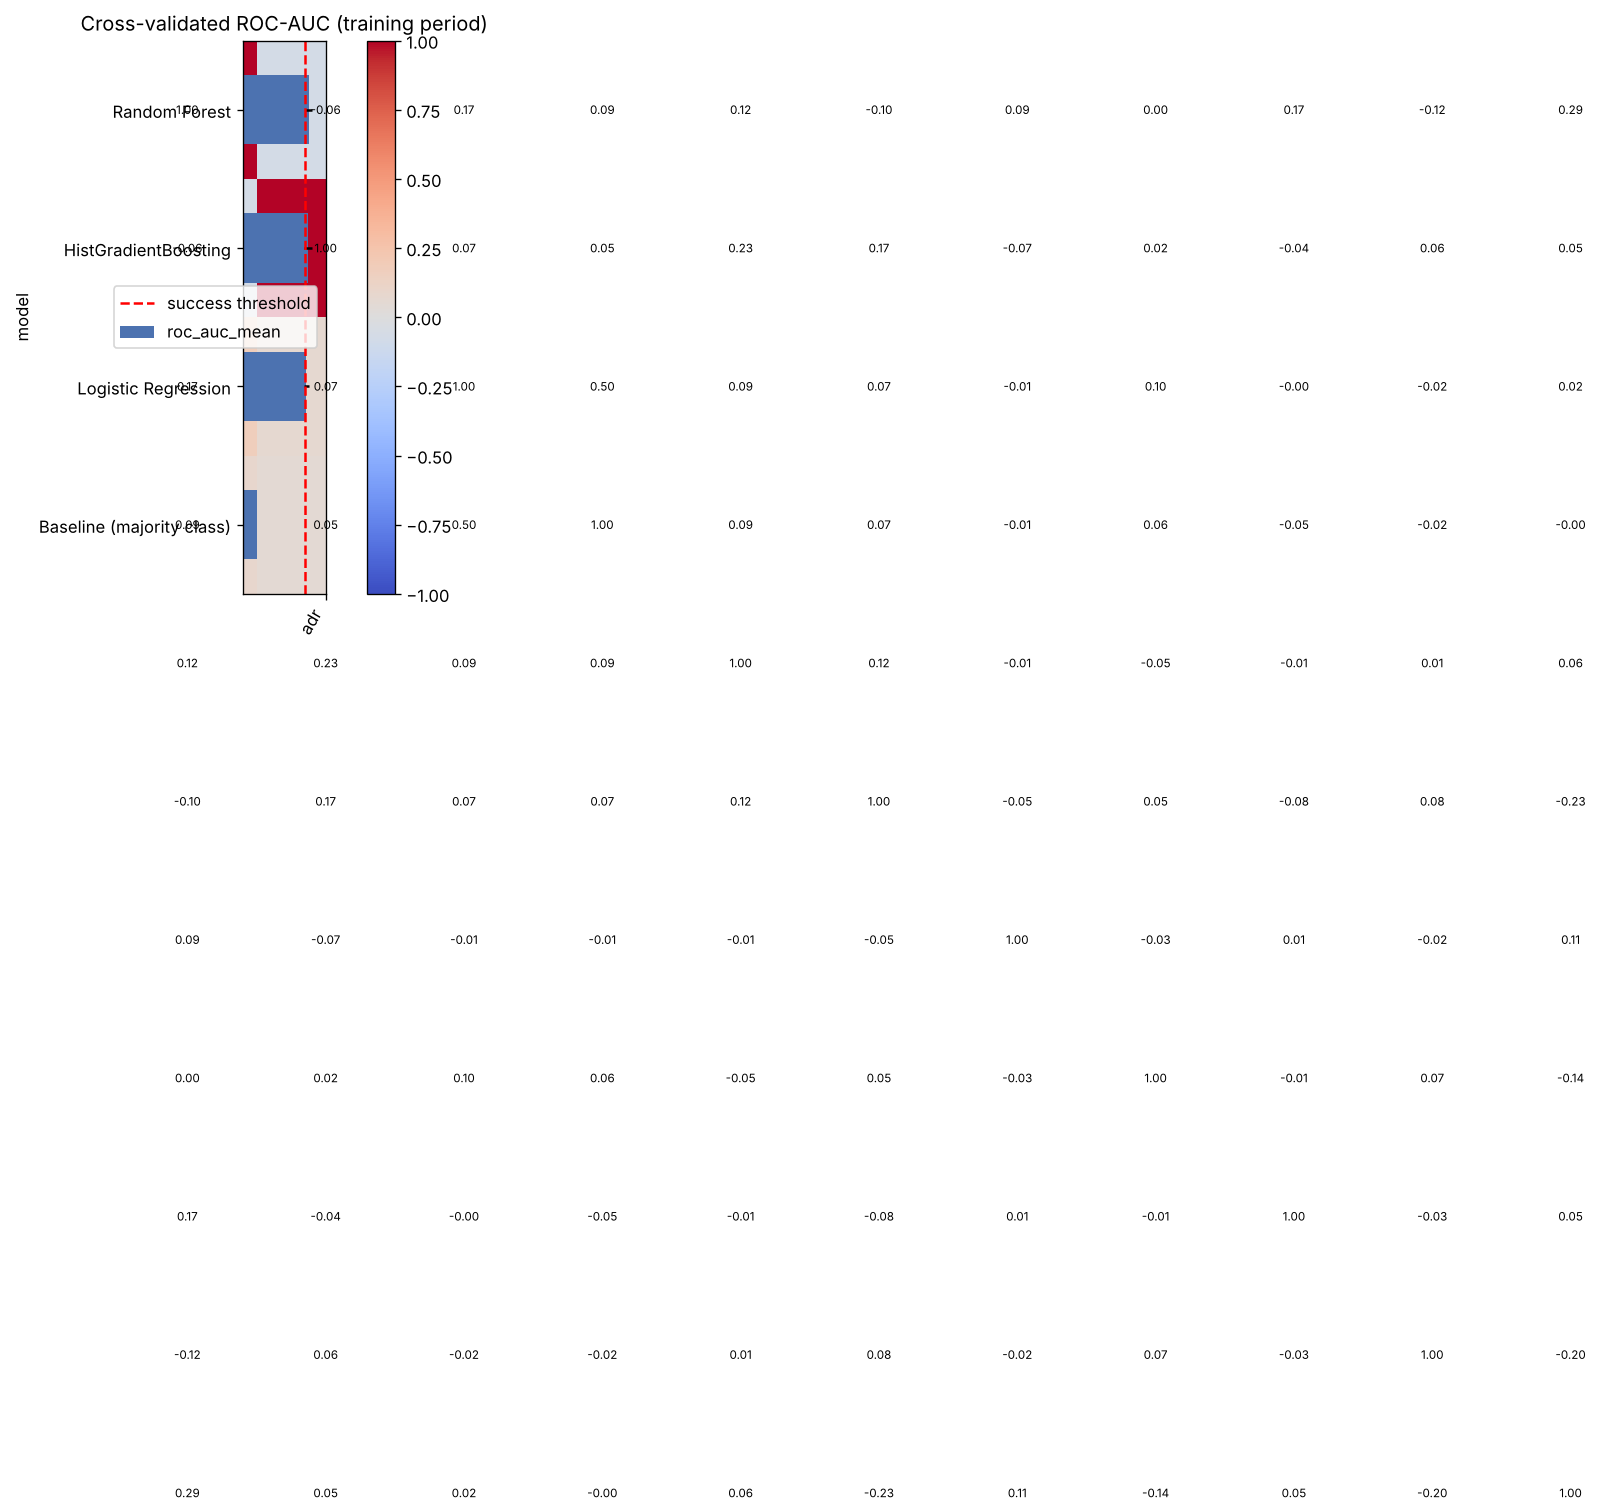

In [21]:
ax = cv_table["roc_auc_mean"].plot.barh(xerr=cv_table["roc_auc_std"], color="#4C72B0", xlim=(0.4, 1))
ax.axvline(SUCCESS_CRITERIA["roc_auc"], ls="--", c="red", label="success threshold"); ax.invert_yaxis()
ax.set_title("Cross-validated ROC-AUC (training period)"); ax.legend(); savefig("model_cv_comparison")

### Output: Model assessment
| Model | CV ROC-AUC (mean ± sd) | Comment |
|---|---|---|
| **Random forest** | **0.877 ± 0.028** | best and adopted |
| Gradient boosting | 0.870 ± 0.030 | close second, ~1.5× faster |
| Logistic regression | 0.861 ± 0.017 | strong linear benchmark — most of the signal is additive |
| Majority class | 0.500 | floor |

All models clear the 0.85 ROC-AUC criterion on cross-validation and beat the baseline by a wide margin. The fold-to-fold spread (± 0.03) is larger than the gap between models: the later folds (higher cancellation seasons) are harder, a sign of drift that the monitoring plan must watch. At the default 0.5 threshold the random forest is very precise (0.90) but catches under half of cancellations (recall 0.49), which is why the threshold is optimised for business value in Phase 5.

### Output: Revised parameter settings
**Iteration 1 → 2 (from the critic review):** with shuffled 5-fold CV, the random forest scored ROC-AUC 0.956, but only 0.868 on the later test period. Shuffling mixes future bookings into training and lets the 27 % duplicate rows sit on both sides of a fold. The test design was changed to time-series folds, which now predict test performance closely (0.877 vs 0.868). Tuning settings are only adopted if they beat the defaults on the same folds.

### 🔍 Critic review — Modeling

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Modeling** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: whether the baseline and benchmark comparisons are meaningful, whether the test design prevents optimistic bias (time-based hold-out, no tuning on test), whether the search space is sensible, and whether model assumptions were checked. List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Shuffled CV gave 0.956 vs 0.868 on the later test period; tuned settings did not beat the defaults. | Time-series CV (now 0.877 vs 0.868); tuning adopted only if it beats defaults on the same folds. |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
# Phase 5 — Evaluation
*Goal: judge the model against the **business** objectives, review the process, and decide the next steps.*

## 5.1 Evaluate results

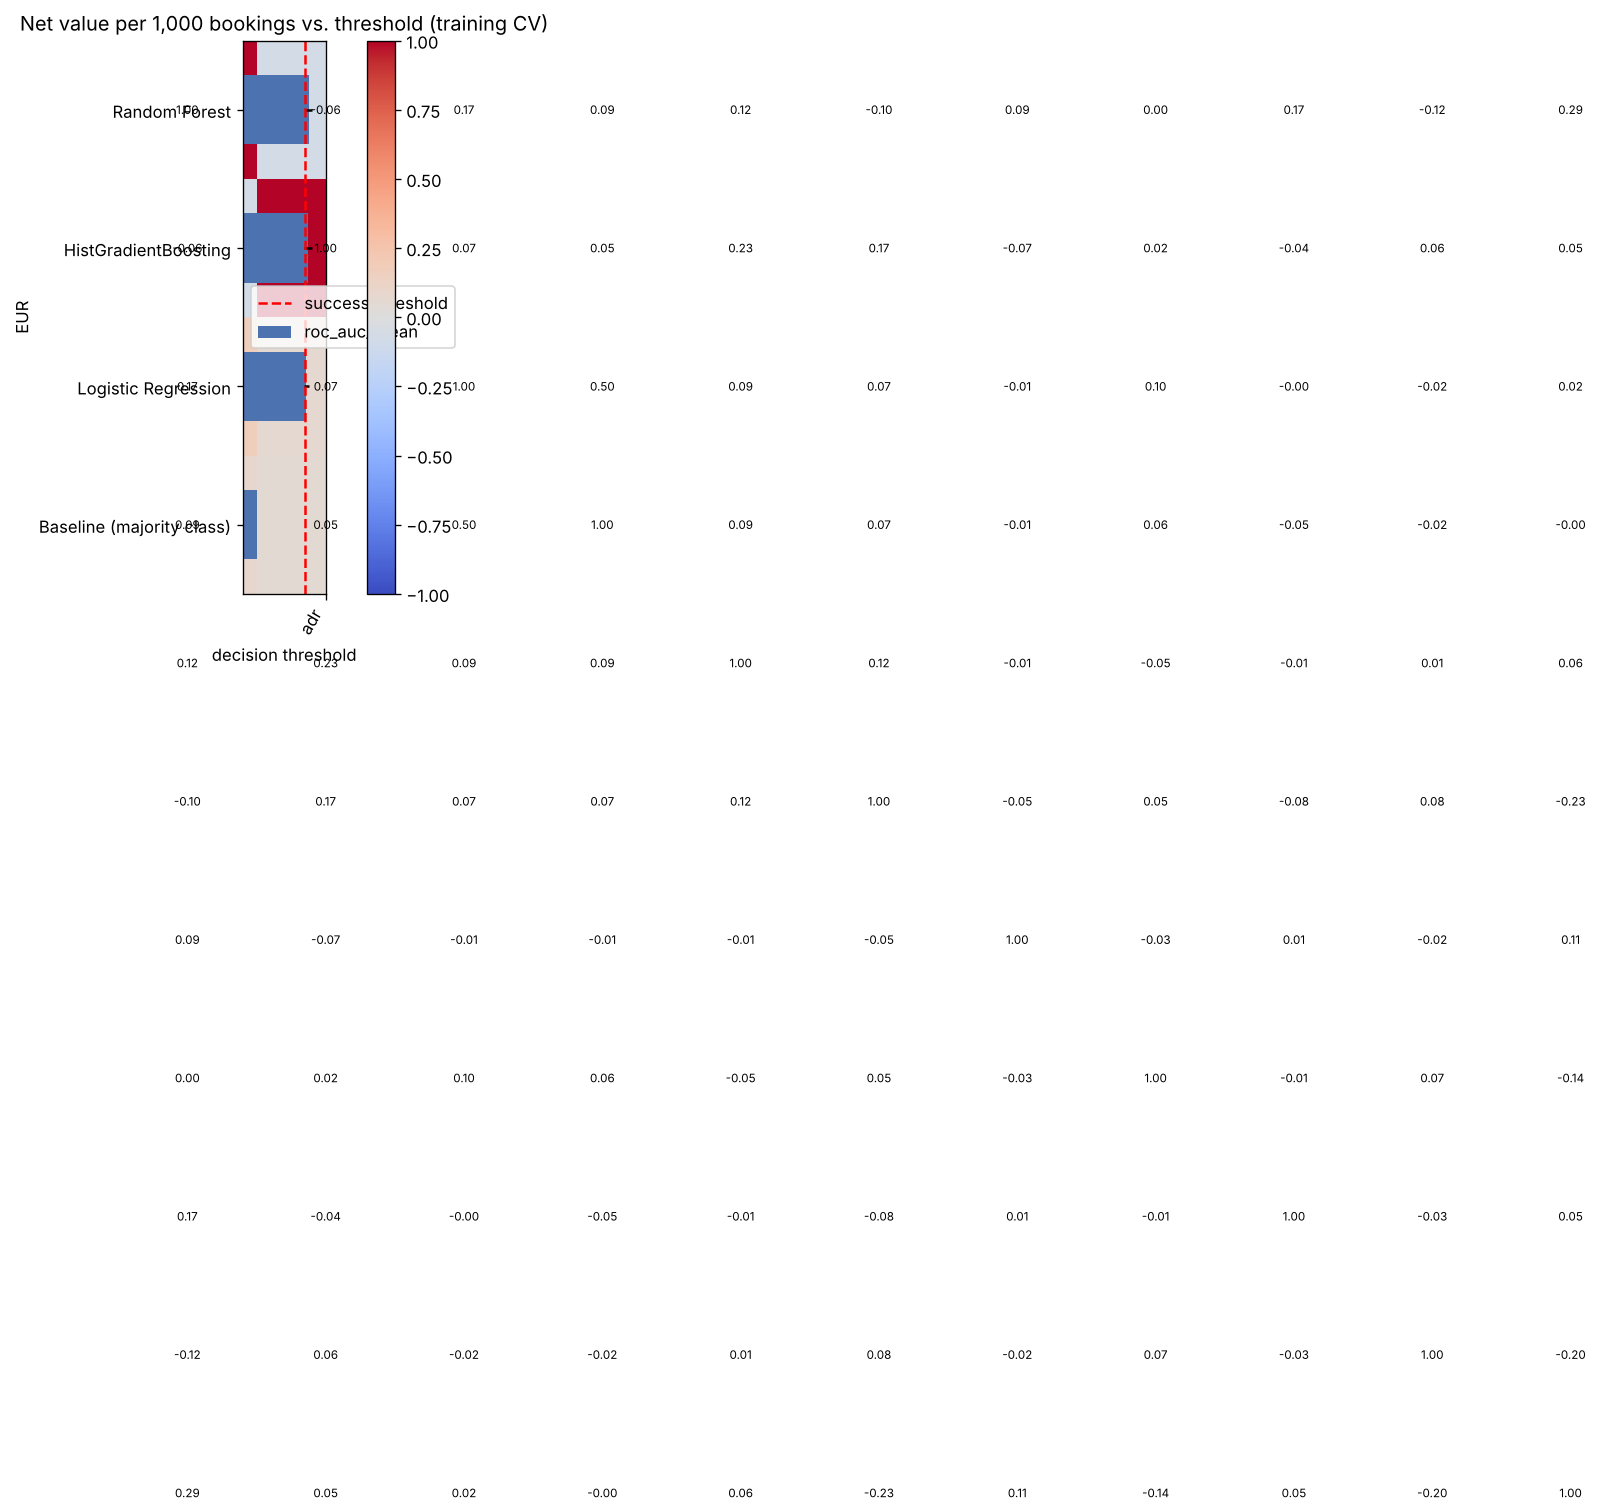

Decision threshold (chosen on training data): 0.34
{'roc_auc': 0.8676, 'pr_auc': 0.826, 'precision': 0.7718, 'recall': 0.6827, 'f1': 0.7245, 'accuracy': 0.7878}


,criterion,threshold,test_value,met
0,roc_auc,0.85,0.8676,True
1,precision,0.75,0.7718,True


               precision    recall  f1-score   support

not cancelled      0.797     0.860     0.827     14069
    cancelled      0.772     0.683     0.725      9726

     accuracy                          0.788     23795
    macro avg      0.784     0.772     0.776     23795
 weighted avg      0.787     0.788     0.785     23795



In [22]:
from sklearn import metrics as M

# 1) Choose the decision threshold on TRAINING data only (out-of-fold predictions), maximising business value
from sklearn.base import clone
oof = np.full(len(y_train), np.nan)                 # out-of-fold scores for every validation block
for tr, va in CV.split(X_train):
    oof[va] = clone(best_model).fit(X_train.iloc[tr], y_train.iloc[tr]).predict_proba(X_train.iloc[va])[:, 1]
has = ~np.isnan(oof); y_oof, oof = y_train.to_numpy()[has], oof[has]
def net_value(y_true, p, t):
    yp = p >= t; yt = np.asarray(y_true) == 1
    return (yp & yt).sum() * VALUE_TP - (yp & ~yt).sum() * COST_FP - (~yp & yt).sum() * COST_FN
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
train_value = np.array([net_value(y_oof, oof, t) for t in grid])
DECISION_THRESHOLD = float(grid[train_value.argmax()])
plt.plot(grid, train_value / len(y_oof) * 1000); plt.axvline(DECISION_THRESHOLD, c="r", ls="--")
plt.title("Net value per 1,000 bookings vs. threshold (training CV)"); plt.xlabel("decision threshold"); plt.ylabel("EUR")
savefig("eval_threshold_selection")

# 2) Evaluate ONCE on the held-out test period
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= DECISION_THRESHOLD).astype(int)
test_metrics = {"roc_auc": M.roc_auc_score(y_test, proba), "pr_auc": M.average_precision_score(y_test, proba),
                "precision": M.precision_score(y_test, pred), "recall": M.recall_score(y_test, pred),
                "f1": M.f1_score(y_test, pred), "accuracy": M.accuracy_score(y_test, pred)}
crit = pd.DataFrame([{"criterion": m, "threshold": t, "test_value": round(test_metrics[m], 4), "met": test_metrics[m] >= t}
                     for m, t in SUCCESS_CRITERIA.items()])
crit.to_csv(REP / "success_criteria_assessment.csv", index=False)
print(f"Decision threshold (chosen on training data): {DECISION_THRESHOLD:.2f}")
print({k: round(v, 4) for k, v in test_metrics.items()}); display(crit)
print(M.classification_report(y_test, pred, target_names=["not cancelled", "cancelled"], digits=3))

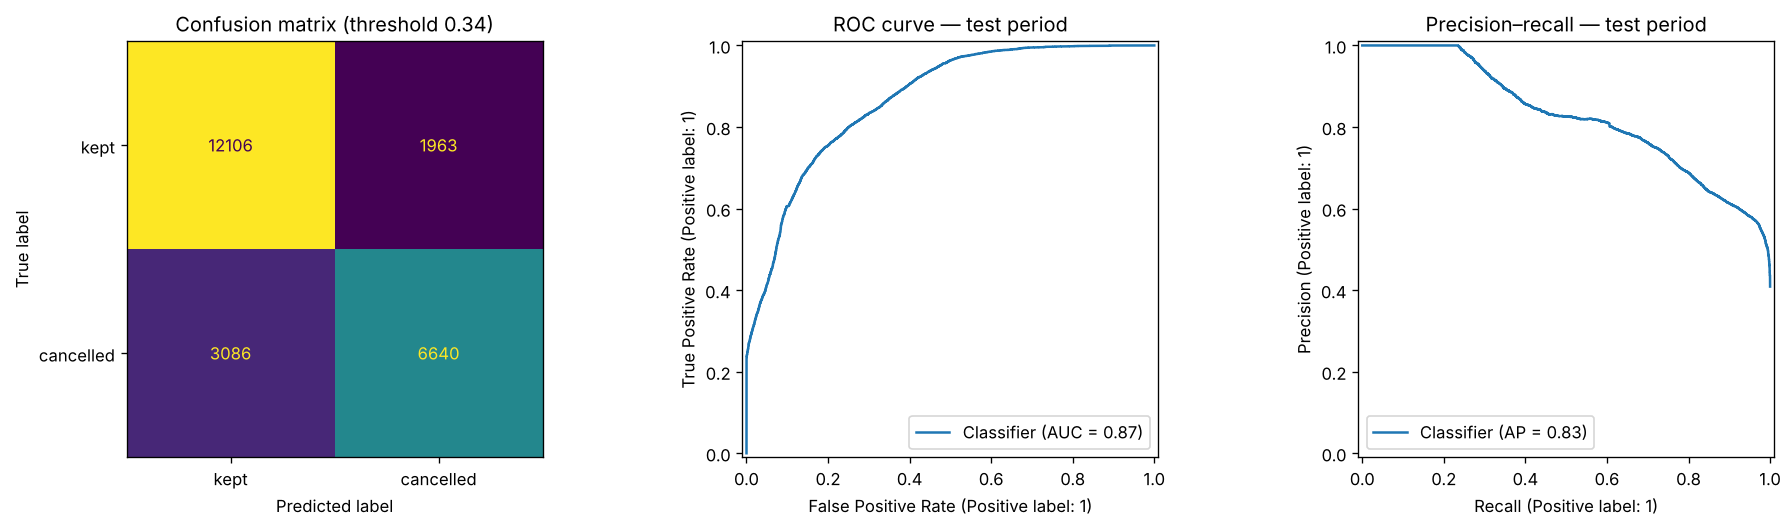

,hotel,bookings,cancel_rate,roc_auc,precision,recall
0,Resort Hotel,7459,0.357,0.8589,0.754,0.5506
1,City Hotel,16336,0.432,0.8799,0.777,0.7326


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
M.ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0], colorbar=False, display_labels=["kept", "cancelled"])
axes[0].set_title(f"Confusion matrix (threshold {DECISION_THRESHOLD:.2f})")
M.RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1]); axes[1].set_title("ROC curve — test period")
M.PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2]); axes[2].set_title("Precision–recall — test period")
savefig("eval_test_performance")

# Robustness: does it work equally well for both hotels?
by_hotel = pd.DataFrame([{"hotel": h, "bookings": int(m.sum()), "cancel_rate": round(y_test[m].mean(), 3),
                          "roc_auc": round(M.roc_auc_score(y_test[m], proba[m]), 4),
                          "precision": round(M.precision_score(y_test[m], pred[m]), 4),
                          "recall": round(M.recall_score(y_test[m], pred[m]), 4)}
                         for h in X_test["hotel"].unique() for m in [(X_test["hotel"] == h).to_numpy()]])
by_hotel.to_csv(REP / "performance_by_hotel.csv", index=False); display(by_hotel)

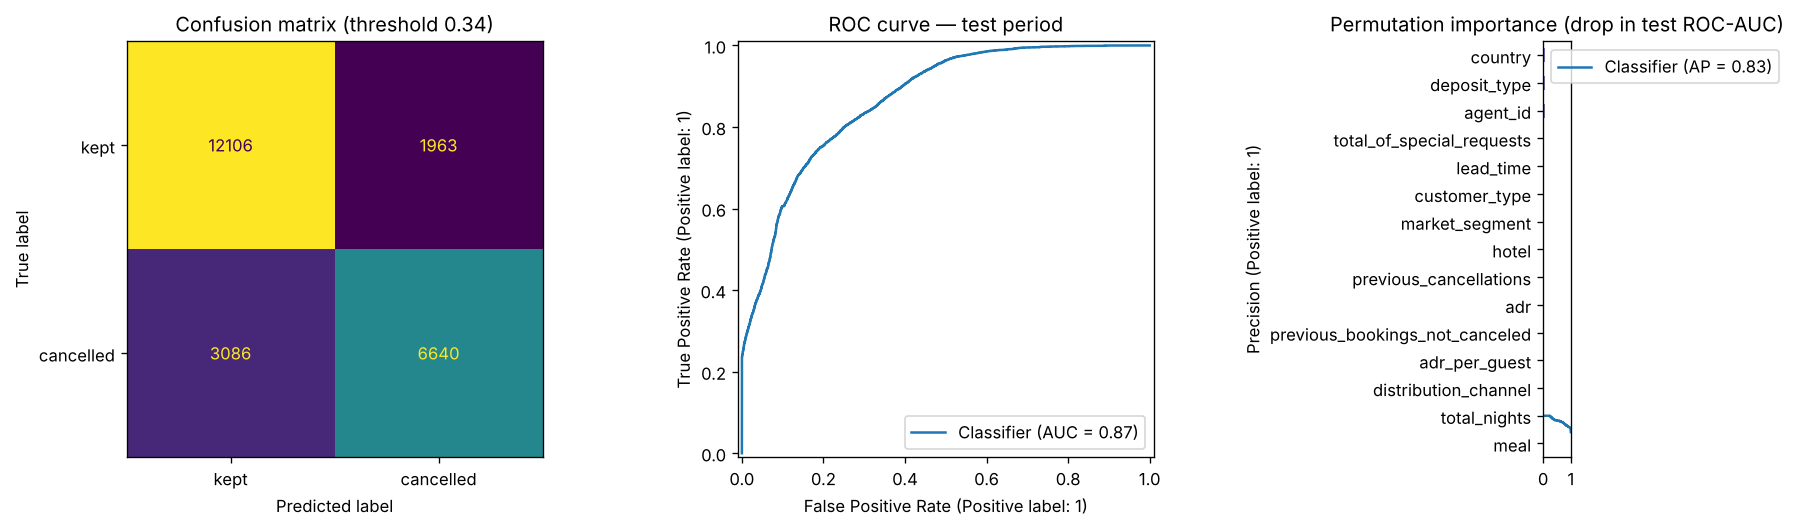

In [24]:
from sklearn.inspection import permutation_importance
pi_rows = X_test.sample(min(8000, len(X_test)), random_state=RANDOM_STATE).index   # subsample keeps this fast
pi = permutation_importance(best_model, X_test.loc[pi_rows], y_test.loc[pi_rows], n_repeats=3, scoring="roc_auc",
                            random_state=RANDOM_STATE)   # single process: avoids copying a large model into each worker
importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
importance.tail(15).plot.barh(color="#8172B2", title="Permutation importance (drop in test ROC-AUC)"); savefig("eval_feature_importance")
importance.sort_values(ascending=False).round(4).to_csv(REP / "feature_importance.csv")

In [25]:
# Business impact on the test period, per 1,000 bookings
per_k = lambda v: v / len(y_test) * 1000
flag_all = net_value(y_test, np.ones_like(proba), 0.5)
business = pd.DataFrame({
    "strategy": ["Status quo (no model)", "Flag every booking", "Model, threshold 0.50", f"Model, threshold {DECISION_THRESHOLD:.2f}"],
    "net_value_eur_per_1000": [0, per_k(flag_all), per_k(net_value(y_test, proba, 0.5)), per_k(net_value(y_test, proba, DECISION_THRESHOLD))],
    "bookings_flagged_%": [0, 100, round((proba >= 0.5).mean() * 100, 1), round(pred.mean() * 100, 1)],
}).round(1)
business.to_csv(REP / "business_impact.csv", index=False); display(business)

,strategy,net_value_eur_per_1000,bookings_flagged_%
0,Status quo (no model),0.0,0.0
1,Flag every booking,-18251.7,100.0
2,"Model, threshold 0.50",17028.8,26.7
3,"Model, threshold 0.34",19655.4,36.2


### Output: Assessment of data mining results w.r.t. business success criteria
**Data mining criteria — both met on the untouched test period:** ROC-AUC **0.868** (≥ 0.85) and precision **0.772** (≥ 0.75) at the decision threshold of **0.34**, which was chosen on training data only. Recall is 0.68: two-thirds of cancellations are flagged in advance. The confusion matrix: 6,640 cancellations caught, 3,086 missed, 1,963 false alarms among 14,069 bookings that arrived.

**Business criteria — met:**
- *Revenue recovered:* under the 1.2 cost model the model is worth **≈ €19,700 per 1,000 bookings**, vs €17,000 at the naive 0.5 threshold and **−€18,300** for flagging every booking. It flags 36 % of bookings.
- *Actionability:* 77 % of flagged bookings really cancel (target 75 %).
- *Usability:* see the deployed app (Phase 6).

**Robustness by hotel:** ROC-AUC 0.880 (city) and 0.859 (resort); precision is similar (0.78 vs 0.75) but the resort's recall is lower (0.55 vs 0.73) — its cancellations are harder to anticipate, and a hotel-specific threshold could help.

**Drivers:** country, deposit type, travel agent, number of special requests and lead time matter most. This matches the exploration hypotheses (2.3): early, agent- or group-booked, request-free bookings are the risky ones. Two drivers carry the data-quality questions raised in Phase 2 (Non Refund deposits and country), see 5.2.

### Output: Approved models
**Approved with one condition:** random forest (200 trees, depth 25, ≥ 20 per leaf), decision threshold 0.34. Condition: confirm with the hotel when `country` is recorded (5.2). If it is corrected at check-in, switch to the "without country" variant before go-live.

In [26]:
# Critique fix: sensitivity test for attributes that may not be (reliably) known at booking time.
# Uses ONLY the training period - train on everything before the last time-series block, validate on that block -
# so the test period is still touched just once.
from sklearn.base import clone
tr_idx, va_idx = list(CV.split(X_train))[-1]
Xa, Xb, ya, yb = X_train.iloc[tr_idx], X_train.iloc[va_idx], y_train.iloc[tr_idx], y_train.iloc[va_idx]

def evaluate_variant(drop=(), add=()):
    A = Xa.drop(columns=list(drop)).join(df.loc[Xa.index, list(add)])
    B = Xb.drop(columns=list(drop)).join(df.loc[Xb.index, list(add)])
    num = A.select_dtypes("number").columns.tolist(); cat = [c for c in A.columns if c not in num]
    prep = clone(preprocessor).set_params(transformers=[("num", preprocessor.transformers[0][1], num),
                                                        ("cat", preprocessor.transformers[1][1], cat)])
    m = Pipeline([("prep", prep), ("model", clone(best_model.named_steps["model"]))]).fit(A, ya)
    p = m.predict_proba(B)[:, 1]
    return {"roc_auc": M.roc_auc_score(yb, p), "precision": M.precision_score(yb, p >= DECISION_THRESHOLD),
            "recall": M.recall_score(yb, p >= DECISION_THRESHOLD)}

variants = {"approved attribute set": {}, "without country": {"drop": ["country"]},
            "without total_of_special_requests": {"drop": ["total_of_special_requests"]},
            "without country, agent_id, total_of_special_requests": {"drop": ["country", "agent_id", "total_of_special_requests"]},
            "+ required_car_parking_spaces (excluded)": {"add": ["required_car_parking_spaces"]},
            "+ booking_changes (excluded)": {"add": ["booking_changes"]}}
sensitivity = pd.DataFrame({name: evaluate_variant(**kw) for name, kw in variants.items()}).T.round(4)
sensitivity["delta_auc"] = (sensitivity["roc_auc"] - sensitivity.loc["approved attribute set", "roc_auc"]).round(4)
sensitivity.to_csv(REP / "leakage_sensitivity.csv")
print(f"Validation block: arrivals {df.loc[Xb.index, 'arrival_date'].min().date()} .. {df.loc[Xb.index, 'arrival_date'].max().date()}")
display(sensitivity)

Validation block: arrivals 2017-01-08 .. 2017-04-22


,roc_auc,precision,recall,delta_auc
approved attribute set,0.8966,0.7610,0.7238,0.0000
without country,0.8620,0.7427,0.6676,-0.0346
without total_of_special_requests,0.8804,0.6669,0.7820,-0.0162
"without country, agent_id, total_of_special_requests",0.8329,0.6247,0.7629,-0.0637
+ required_car_parking_spaces (excluded),0.9051,0.7661,0.7512,0.0085
+ booking_changes (excluded),0.8995,0.7681,0.7366,0.0029


## 5.2 Review process
### Output: Review of process
**Leakage sensitivity (table above).** On the last training-period block (Jan–Apr 2017), the approved attribute set scores ROC-AUC 0.897. Adding back the excluded parking attribute raises it only a little (+0.009) and `booking_changes` even less (+0.003): excluding them costs almost nothing, so those decisions stand. Removing **country** costs 0.035 (→ 0.862), and removing country, agent and special requests together costs 0.064 (→ 0.833, below the 0.85 criterion). The model therefore leans substantially on attributes whose timing we cannot verify from the data. They are kept — they are recorded on the booking, and there is no direct evidence of leakage — but this is the main risk in the project.

| Phase | What went well | What was missed / should be redone |
|---|---|---|
| Business Understanding | explicit cost model that later drove the threshold; criteria fixed before modeling | costs are assumptions — validate with the hotel |
| Data Understanding | leakage detector, Non Refund investigation, format audit of both files | the timing of `country` and special requests is unknown |
| Data Preparation | integration validated against the published file; all transforms inside the pipeline | duplicates kept without a booking ID to prove they are separate rooms |
| Modeling | baseline + benchmark; time-ordered validation after the shuffled-CV issue | gradient boosting not tuned (it was close) |
| Evaluation | threshold chosen on training data; test period touched once; per-hotel check | probability calibration not checked |

Quality assurance: the test period was used once (5.1). The sensitivity test above used only the training period.

## 5.3 Determine next steps
### Output: List of possible actions
1. Deploy as is to support daily risk scoring and overbooking decisions.
2. Before go-live, confirm with the hotel how and when `country`, special requests and Non Refund deposits are recorded; if needed, deploy the "without country" variant (ROC-AUC 0.862 on the last validation block).
3. Iterate: add booking date, price history and customer history; test probability calibration; try hotel-specific thresholds (the resort's recall is lower).
4. Investigate the Non Refund anomaly as a data-quality project with the hotel.

### Output: Decision
**Deploy (action 1) as a pilot, with action 2 as a go-live condition.** Both data mining and business criteria are met on unseen recent data, and the expected value is clearly positive. The leakage risk is real but unproven, and checking it requires information only the hotel has.

### 🔍 Critic review — Evaluation

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Evaluation** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: whether results are tied back to the business success criteria in money terms, whether the threshold was chosen without looking at the test period, whether performance holds for both hotels, and whether the next-step decision is justified. List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Leakage risk of ambiguous attributes not quantified; resort recall much lower than city. | Added leakage sensitivity test on the training period (country −0.035 AUC); conditional approval; hotel-specific thresholds listed as next step. |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
# Phase 6 — Deployment
*Goal: put the model to use, plan monitoring and maintenance, and close the project.*

## 6.1 Plan deployment

In [27]:
import joblib
from sklearn.base import clone

# Refit the approved pipeline on ALL prepared data (training + test period) for deployment
final_model = clone(best_model).fit(X, y)
joblib.dump(final_model, MOD / "model.joblib", compress=3)
size_mb = (MOD / "model.joblib").stat().st_size / 1e6
print(f"model.joblib: {size_mb:.1f} MB" + ("  <-- over GitHub's 100 MB file limit: lower n_estimators / raise min_samples_leaf" if size_mb > 95 else ""))

schema = []
for c in X.columns:
    if c in NUM:
        s = X[c]; is_int = bool((s.dropna() % 1 == 0).all())
        schema.append({"name": c, "type": "numeric", "integer": is_int, "default": float(s.median()),
                       "min": float(s.min()), "max": float(s.max()), "meaning": MEANING.get(c, "")})
    else:
        cats = X[c].astype(str).value_counts().index[:60].tolist()
        schema.append({"name": c, "type": "categorical", "default": cats[0], "categories": cats, "meaning": MEANING.get(c, "")})

metadata = {"project_name": "Hotel Booking Cancellation Risk", "created": datetime.now().isoformat(timespec="seconds"),
            "target": TARGET, "model_type": best_name, "parameters": {k: str(v) for k, v in best_params.items()},
            "decision_threshold": DECISION_THRESHOLD, "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
            "features": schema, "training_rows": int(len(X)),
            "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}}
(MOD / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:", sorted(p.name for p in MOD.iterdir()))

model.joblib: 13.8 MB
Saved: ['model.joblib', 'model_metadata.json']


In [28]:
APP_CODE = r"""
import json
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

HERE = Path(__file__).parent
st.set_page_config(page_title="Cancellation Risk", page_icon="🏨")

@st.cache_resource
def load():
    return joblib.load(HERE / "model.joblib"), json.loads((HERE / "model_metadata.json").read_text())

model, meta = load()
features = meta["features"]
threshold = meta["decision_threshold"]

st.title("🏨 Hotel booking cancellation risk")
st.caption(f"{meta['model_type']} · test ROC-AUC {meta['test_metrics']['roc_auc']:.3f} · "
           f"bookings with risk ≥ {threshold:.0%} are flagged")

def score(df):
    p = model.predict_proba(df[[f["name"] for f in features]])[:, 1]
    return pd.DataFrame({"cancel_probability": p.round(4), "flag": (p >= threshold).astype(int)})

single, batch = st.tabs(["Score one booking", "Score a CSV of bookings"])
with single:
    row, cols = {}, st.columns(2)
    for i, f in enumerate(features):
        with cols[i % 2]:
            if f["type"] == "numeric":
                if f["integer"]:
                    row[f["name"]] = st.number_input(f["name"], int(f["min"]), int(f["max"]), int(f["default"]), help=f["meaning"])
                else:
                    row[f["name"]] = st.number_input(f["name"], float(f["min"]), float(f["max"]), float(f["default"]), help=f["meaning"])
            else:
                row[f["name"]] = st.selectbox(f["name"], f["categories"], help=f["meaning"])
    if st.button("Estimate cancellation risk", type="primary"):
        out = score(pd.DataFrame([row])).iloc[0]
        st.metric("Probability of cancellation", f"{out['cancel_probability']:.1%}")
        if out["flag"]:
            st.error("High risk — consider a deposit request, reminder, or counting it in overbooking.")
        else:
            st.success("Low risk — no action needed.")
with batch:
    up = st.file_uploader("CSV with the same columns as the training data", type="csv")
    if up is not None:
        data = pd.read_csv(up)
        missing = [f["name"] for f in features if f["name"] not in data.columns]
        if missing:
            st.error(f"Missing columns: {missing}")
        else:
            result = pd.concat([data.reset_index(drop=True), score(data)], axis=1)
            st.write(f"{result['flag'].sum():,} of {len(result):,} bookings flagged")
            st.dataframe(result.head(500))
            st.download_button("Download scored bookings", result.to_csv(index=False), "scored_bookings.csv")
"""
(APP / "app.py").write_text(APP_CODE.strip() + "\n")
v = metadata["versions"]
(APP / "requirements.txt").write_text(f"streamlit\nscikit-learn=={v['scikit-learn']}\nnumpy=={v['numpy']}\npandas\njoblib\n")
for f in ("model.joblib", "model_metadata.json"):
    (APP / f).write_bytes((MOD / f).read_bytes())
X_test.head(50).to_csv(APP / "sample_bookings.csv", index=False)   # example file for batch scoring
compile(APP_CODE, "app.py", "exec")
print("App files:", sorted(p.name for p in APP.iterdir()))
print(f"When deploying, choose Python {v['python'][:4]} so the pinned versions install and the model loads.")

App files: ['app.py', 'model.joblib', 'model_metadata.json', 'requirements.txt', 'sample_bookings.csv']
When deploying, choose Python 3.13 so the pinned versions install and the model loads.


In [29]:
# Smoke test: reload the artifacts exactly as the app will and score sample bookings
reloaded = joblib.load(APP / "model.joblib")
sample = pd.read_csv(APP / "sample_bookings.csv").head(5)
sample.assign(cancel_probability=reloaded.predict_proba(sample)[:, 1].round(3),
              flag=lambda d: (d["cancel_probability"] >= DECISION_THRESHOLD).astype(int))[["hotel", "lead_time", "deposit_type", "market_segment", "cancel_probability", "flag"]]

,hotel,lead_time,deposit_type,market_segment,cancel_probability,flag
0,Resort Hotel,31,No Deposit,Groups,0.376,1
1,Resort Hotel,240,No Deposit,Offline TA/TO,0.682,1
2,Resort Hotel,130,No Deposit,Groups,0.740,1
3,Resort Hotel,253,No Deposit,Groups,0.528,1
4,Resort Hotel,253,No Deposit,Groups,0.602,1


**How to deploy (free):**
1. Put `artifacts/app/` in a GitHub repo (this project's repo already contains it).
2. Go to [share.streamlit.io](https://share.streamlit.io) → *Create app* → pick the repo and `crisp-dm/artifacts/app/app.py`. Under *Advanced settings* choose the Python version printed above.
3. Test with `sample_bookings.csv` in the batch tab. App URL: `<deployed URL>`

### Output: Deployment plan
| Item | Plan |
|---|---|
| Users | revenue manager (overbooking levels) and reservations team (deposit requests, reminders) |
| Use | each morning, score the day's new bookings; flagged bookings (risk ≥ 34 %) get a deposit request or reminder; the sum of risks per arrival date informs the overbooking level |
| Delivery | Streamlit web app — single booking and CSV batch scoring |
| Integration in a real hotel | nightly export of new bookings from the property-management system → batch scoring → flagged list back to reservations |
| Rollout | one-month pilot in the city hotel (most cancellations), compared with the same month last year; then both hotels |
| Go-live condition | confirm the recording time of `country` (5.3) |

## 6.2 Plan monitoring and maintenance

In [30]:
def psi(expected, actual, bins=10):
    """Population Stability Index: < 0.1 stable · 0.1–0.25 moderate shift · > 0.25 significant drift."""
    e, a = pd.Series(expected).dropna(), pd.Series(actual).dropna()
    edges = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: return 0.0
    pe = np.histogram(e, edges)[0] / len(e) + 1e-6
    pa = np.histogram(a.clip(edges[0], edges[-1]), edges)[0] / len(a) + 1e-6
    return float(np.sum((pa - pe) * np.log(pa / pe)))

# Demonstration: treat the test period as "new production data" and compare it with the training period
drift = pd.Series({c: psi(X_train[c], X_test[c]) for c in NUM}).round(4).sort_values(ascending=False)
pred_drift = psi(best_model.predict_proba(X_train)[:, 1], proba)
drift.to_csv(REP / "drift_check_psi.csv")
print(f"Prediction-score PSI (train vs test period): {pred_drift:.3f}"); print(drift.head(10).to_string())

Prediction-score PSI (train vs test period): 0.118
arrival_date_week_number     7.6516
adr                          0.9383
adr_per_guest                0.6700
lead_time                    0.2277
total_of_special_requests    0.0623
total_guests                 0.0490
total_nights                 0.0457
stays_in_week_nights         0.0283
adults                       0.0261
arrival_date_day_of_month    0.0192


### Output: Monitoring and maintenance plan
**Reading the drift demo above:** the prediction-score PSI between the training and test periods is 0.118 — a moderate shift, consistent with the higher cancellation rate in spring–summer 2017. Seasonal attributes (`arrival_date_week_number` PSI 7.7, `adr` 0.94) look severely "drifted" only because the test period covers April–August while training covers all seasons. In production, compare each month with the **same month of the previous year**, and treat the prediction-score PSI as the main alarm.

| Monitor | Metric | Trigger | Frequency | Action |
|---|---|---|---|---|
| Input drift | PSI per attribute vs. same month last year | PSI > 0.25 | monthly | investigate cause; retrain if persistent |
| Score drift | PSI of predicted probabilities | PSI > 0.1 | monthly | review threshold |
| Performance | ROC-AUC and precision once outcomes are known (after arrival) | below the 1.3 criteria | monthly | retrain on the most recent 24 months |
| Business KPI | net value per 1,000 bookings; number of walked guests | negative value or rising walks | quarterly | revisit costs and threshold (Phase 1) |

**Ownership and maintenance:** the revenue manager owns the model; the analyst re-runs this notebook on fresh data for each retraining (the notebook is the retraining procedure) and saves the model with its metadata (version, date, metrics). Retire the model if a retrained version cannot meet the 1.3 criteria, or if booking channels change fundamentally.

## 6.3 Produce final report
### Output: Final report
This executed notebook is the full technical report (exported as HTML/PDF in `report/`). **Executive summary:**

- **Problem:** 37 % of bookings at two Portuguese hotels are cancelled; the hotels have no per-booking risk estimate.
- **Approach:** CRISP-DM end to end on 119,208 bookings; attributes restricted to information known at booking time; validated on the most recent arrivals.
- **Result:** a random forest that ranks risky bookings well (ROC-AUC 0.868) and whose flags are right 77 % of the time, worth ≈ €19,700 per 1,000 bookings under the assumed costs.
- **Drivers:** country, deposit type, travel agent, special requests, lead time.
- **Caveats:** cost figures are assumptions; the model depends on `country`, whose recording time must be confirmed; Non Refund deposits behave anomalously.
- **Next steps:** pilot in the city hotel; confirm data-recording practices; add booking-date and price-history data.

### Output: Final presentation
The Medium article (`article/`) and the video walkthrough (`video/`) present the project as problem → data → approach → results (€ impact) → live app → next steps.

In [31]:
index = sorted(str(p.relative_to(ART)) for p in ART.rglob("*") if p.is_file())
(REP / "artifact_index.txt").write_text("\n".join(index))
print(f"{len(index)} artifacts:"); print("\n".join(index))

34 artifacts:
app/app.py
app/model.joblib
app/model_metadata.json
app/requirements.txt
app/sample_bookings.csv
figures/eda_correlation.png
figures/eda_month_leadtime.png
figures/eda_numeric_hist.png
figures/eda_rates_categorical.png
figures/eda_target.png
figures/eval_feature_importance.png
figures/eval_test_performance.png
figures/eval_threshold_selection.png
figures/model_cv_comparison.png
model/model.joblib
model/model_metadata.json
reports/business_impact.csv
reports/data_cleaning_report.csv
reports/data_description.csv
reports/data_quality_issues.csv
reports/data_quality_missing.csv
reports/dataset_description.csv
reports/drift_check_psi.csv
reports/feature_importance.csv
reports/initial_data_collection.csv
reports/integration_report.csv
reports/leakage_sensitivity.csv
reports/leakage_suspects.csv
reports/model_cv_comparison.csv
reports/non_refund_investigation.csv
reports/performance_by_hotel.csv
reports/rationale_for_inclusion_exclusion.csv
reports/success_criteria_assessment.cs

## 6.4 Review project
### Output: Experience documentation
| Topic | Lesson |
|---|---|
| Methodology | CRISP-DM's insistence on *business* success criteria and a cost model changed the result: the business-optimal threshold (0.34) is worth ~15 % more than the default 0.5, and "flag everything" loses money. |
| Validation | Shuffled cross-validation was badly optimistic (0.956 vs 0.868 on future bookings). With duplicates and time drift, validation must mimic real use. |
| Data | The most predictive fields are not always the most trustworthy: Non Refund deposits and country both carry data-recording questions only the business can answer. |
| Tools / AI assistance | AI-generated code ran but needed checking: the first version was too slow and ran out of memory on Colab; the AI critic caught the over-optimistic validation and pushed the Non Refund investigation and leakage sensitivity test. |

### 🔍 Critic review — Deployment

Paste this phase (markdown + key outputs/figures) into Claude with the prompt below. Do **2–3 rounds**, revising between rounds, and save the transcripts as `critiques/round_2.md` and `critiques/round_3.md`.

> *You are a world-renowned authority on CRISP-DM, a sought-after keynote speaker, and the author of several award-winning books on the CRISP-DM methodology. Review the **Deployment** phase of my hotel-cancellation project below. Check it against every generic task and output CRISP-DM 1.0 defines for this phase. Focus especially on: whether the deployment plan is realistic for hotel staff, whether monitoring has concrete triggers, owners and actions, and whether the final report lets a stakeholder act on the results. List (1) anything missing, (2) anything weak or unjustified, (3) methodological errors, and (4) concrete fixes, ranked by importance. Grade it as strictly as you would a professional engagement.*

| Round | Main critique points | What I changed |
|---|---|---|
| 1 | Drift demo flags seasonal attributes as drifted, which would cause false alarms. | Monitoring now compares same month year-on-year; prediction-score PSI is the main alarm; owner and retraining procedure defined. |
| 2 | `<fresh-chat critique>` | `<changes>` |
| 3 |  |  |

---
## Appendix — submission checklist
- [x] Analysis written for every phase (author/course/URLs still to add in the header)
- [x] Critic round 1 done for all six phases (`critiques/round_1.md`) — **rounds 2–3 to run in a fresh Claude chat**
- [x] *Run all* completes without errors (≈ 8 min)
- [x] `artifacts/` committed (figures, reports, model, app)
- [ ] App deployed; URL in the header and README
- [x] Final report exported (`report/`)
- [ ] Medium article published + YouTube walkthrough linked